# 🥋 JAC-ECC 2026 — Master Validation Pipeline (One-Notebook Replication of the App)

**Purpose:** Replicate the full production pipeline *outside* the app so every claim in the resubmission paper can be regenerated from one notebook:

| Part | What it does | Mirrors |
|---|---|---|
| **§1** | Data audit — clips per practitioner, train/test split, leakage check | `01_DualStem_Training2.ipynb` §2 |
| **§2** | Model tournament + **5-fold practitioner-disjoint CV**: Single Bi-LSTM, Dual-Stem Fusion, XGBoost, Random Forest (accuracy + macro-F1, all-pairs paired tests with Holm correction) + golden split for **all four** models | `01_BiLSTM_Tournament.ipynb`, `run_5fold_cv.py`, Training2 §7/§11 |
| **§3** | Extract the **NEW Master GT** (isolated textbook moves, Savitzky-Golay w=5, stance-specific keys) | `scripts/extract_master_reference.py` |
| **§4** | Classify the **11 held-out trainee videos** with all four models | `routers/classify.py` |
| **§5** | OOD cascade (softmax → margin → DTW) with **FPR + FRR + ROC/AUROC** | `ood_config.py` Layer 1–3 |
| **§6** | DTW feedback replication: mirroring, peak-deviation errors, mean-vs-max proof plot | `rag/dtw_comparator.py` |
| **§7** | RAG ablation: Rule templates vs Direct LLM vs RAG+LLM (offline fallback if no API key) | `rag/retriever.py`, `rag/llm_client.py` |

**Run order:** §1→§2 (training on the 446-clip CSV) → §3 (needs the new Master videos folder) → §4→§7 (needs the 9 trainee videos folder).


In [1]:
# ── 0. Imports & Configuration ───────────────────────────────────────────────
import os, re, sys, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import savgol_filter
from scipy.stats import ttest_rel
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             f1_score, roc_curve, auc)
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
tf.random.set_seed(42); np.random.seed(42)

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.facecolor': '#0D1117', 'axes.facecolor': '#161B22',
                     'axes.edgecolor': '#30363D', 'text.color': 'white',
                     'axes.labelcolor': 'white', 'xtick.color': 'white', 'ytick.color': 'white'})

# ══════════════════ EDIT THESE THREE PATHS ══════════════════
CSV_PATH        = r"D:\CS-Senior26'\GR\martial-arts-trainer\backend\app\data\karate_normalized_base.csv"
MASTER_GT_DIR   = r"D:\CS-Senior26'\GR\martial-arts-trainer\backend\app\data\Examplers"      # 18 clips: <Move>_<stance>.mp4  (§3)
TRAINEE_VID_DIR = r"D:\CS-Senior26'\GR\Karate_phase\segmentedTest"     # 9 clips: MaeGeri_side_048_0002.mp4 (§4)
RESULTS_DIR     = Path("Results/master_validation"); RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SEQ_LEN, N_CLASSES, RANDOM_SEED = 30, 3, 42
print("✅ Config ready")


✅ Config ready


In [2]:
import os
import sys
sys.path.insert(0, r"D:\CS-Senior26'\GR\martial-arts-trainer\backend")

# 1. Load environment variables (GROQ_API_KEY etc.)
try:
    from dotenv import load_dotenv
    load_dotenv()
except Exception as _e:
    print(f"[setup] python-dotenv not available ({_e}) - relying on the process environment.")

# 2. Database is NOT needed for this notebook (it only reads the CSV/videos and writes to Results/).
#    Initialise it if it is reachable, but never let a missing Postgres stop the run.
try:
    from app.database import init_db
    init_db()
    print("Database connection established.")
except BaseException as _e:
    print(f"[setup] Database not initialised ({type(_e).__name__}: {str(_e)[:100]}) - not required here, continuing.")

# LLM client lazy-loads automatically in section 7.
print("LLM client ready.")

Database connection established.
LLM client ready.


## §1 — Dataset Audit: Clips per Practitioner & Split Policy
**[Reviewers A/B/C: "the split policy is not stated"]** — this section produces exactly the numbers you quote in Section IV of the paper: per-practitioner clip counts, train/test totals, and a programmatic zero-leakage proof.


In [3]:
# ── §1. Dataset Audit — clips per practitioner, split policy, leakage check ──
df = pd.read_csv(CSV_PATH)
print(f"Loaded: {len(df):,} rows × {df.shape[1]} cols")

le = LabelEncoder()
df['label_enc'] = le.fit_transform(df['folder_label'])
CLASS_NAMES = le.classes_.tolist()          # e.g. ['GedanBarai', 'Gyakudzuki', 'MaeGeri']
N_CLASSES   = len(CLASS_NAMES)
print(f"Classes ({N_CLASSES}): {CLASS_NAMES}")

def extract_practitioner_and_view(clip_name):
    """Filename convention: <Move>_<view>_<practitioner>_<clipnum>  e.g. GedanBarai_side_048_0002"""
    parts = clip_name.split('_')
    if len(parts) >= 4:
        return parts[2], parts[1]           # practitioner_id, view
    return "Unknown", "Unknown"

clip_meta = []
for clip_id, grp in df.groupby('clip_id'):
    prac, view = extract_practitioner_and_view(clip_id)
    clip_meta.append({'clip_id': clip_id, 'label_enc': grp['label_enc'].iloc[0],
                      'folder_label': grp['folder_label'].iloc[0],
                      'practitioner_id': prac, 'view': view})
meta_df = pd.DataFrame(clip_meta)

# ── FIX 1 (leakage): exclude the people who also appear in the Master/exemplar and Trainee videos.
# Practitioners 048-051 were used as DTW reference / trainee test subjects, so keeping their
# clips in train/test makes the reference circular and the trainee test not truly held out.
EXCLUDE_PRACTITIONERS = {'048', '049', '050', '051'}      # edit if your exemplar/trainee IDs differ
_excl = meta_df[meta_df['practitioner_id'].isin(EXCLUDE_PRACTITIONERS)]
print(f"Excluding {len(_excl)} clips from practitioners {sorted(EXCLUDE_PRACTITIONERS)} "
      f"(exemplar/trainee identities) from train/test/CV.")
meta_df = meta_df[~meta_df['practitioner_id'].isin(EXCLUDE_PRACTITIONERS)].reset_index(drop=True)
df = df[df['clip_id'].isin(meta_df['clip_id'])].reset_index(drop=True)
N_CLIPS = len(meta_df)
print(f"\nTotal clips: {N_CLIPS} | Total frames: {len(df):,} | frames/clip: {len(df)//N_CLIPS}")

# ── Split policy (same golden test override as the app-training notebook) ─────
TRAIN_PRACTITIONERS = {'026','015','014','044','047','050','027','010','051','025','001','039',
                       '037','034','045','040','032','002','038','019','029','041','007','009',
                       '030','012','031','016','006','036','057','058','042','008','021','033',
                       '004','018','022','048','013','017','035'}
TEST_PRACTITIONERS  = {'056','055','024','011','046','049','020','043','005','023','003','053'}

TRAIN_PRACTITIONERS = TRAIN_PRACTITIONERS - EXCLUDE_PRACTITIONERS
TEST_PRACTITIONERS  = TEST_PRACTITIONERS  - EXCLUDE_PRACTITIONERS
meta_df['split'] = np.where(meta_df['practitioner_id'].isin(TEST_PRACTITIONERS), 'test',
                     np.where(meta_df['practitioner_id'].isin(TRAIN_PRACTITIONERS), 'train', 'unassigned'))

print("\n📋 CLIPS PER PRACTITIONER (sorted by count)")
per_prac = meta_df.groupby(['practitioner_id','split']).size().unstack(fill_value=0)
per_prac['total'] = per_prac.sum(axis=1)
display(per_prac.sort_values('total', ascending=False))

train_meta = meta_df[meta_df['split']=='train']
test_meta  = meta_df[meta_df['split']=='test']
overlap    = set(train_meta['practitioner_id']) & set(test_meta['practitioner_id'])

print(f"\nTrain practitioners: {train_meta['practitioner_id'].nunique()}  |  Train clips: {len(train_meta)}")
print(f"Test  practitioners: {test_meta['practitioner_id'].nunique()}  |  Test  clips: {len(test_meta)}")
print(f"Unassigned clips   : {(meta_df['split']=='unassigned').sum()}  (not used in golden split)")
print(f"🛡️ Leakage overlap: {overlap if overlap else 'set()  ✅ ZERO'}")

print("\n📊 TEST SET BALANCE (class × view):")
print(pd.crosstab(test_meta['folder_label'], test_meta['view'], margins=True))
print("\n📊 TRAIN SET BALANCE (class × view):")
print(pd.crosstab(train_meta['folder_label'], train_meta['view'], margins=True))

train_clips = train_meta['clip_id'].values
test_clips  = test_meta['clip_id'].values
meta_df.to_csv(RESULTS_DIR/'clip_audit.csv', index=False)


# ── FIX 2 (early-stopping bias): practitioner-disjoint validation split carved from TRAINING data only.
# The test set must never be used for early stopping / checkpoint selection.
from sklearn.model_selection import GroupShuffleSplit
PRAC_OF = dict(zip(meta_df['clip_id'], meta_df['practitioner_id']))

def carve_val(clips, frac=0.15, seed=None):
    clips = np.asarray(clips)
    g = np.array([PRAC_OF[c] for c in clips])
    gss = GroupShuffleSplit(n_splits=1, test_size=frac, random_state=RANDOM_SEED if seed is None else seed)
    a, b = next(gss.split(clips, groups=g))
    assert not (set(g[a]) & set(g[b]))
    return clips[a], clips[b]


Loaded: 14,640 rows × 149 cols
Classes (3): ['GedanBarai', 'Gyakudzuki', 'MaeGeri']
Excluding 4 clips from practitioners ['048', '049', '050', '051'] (exemplar/trainee identities) from train/test/CV.

Total clips: 484 | Total frames: 14,520 | frames/clip: 30

📋 CLIPS PER PRACTITIONER (sorted by count)


split,test,train,total
practitioner_id,,,
002,0,46,46
027,0,32,32
003,30,0,30
040,0,28,28
032,0,22,22
012,0,22,22
014,0,21,21
020,20,0,20
038,0,19,19



Train practitioners: 40  |  Train clips: 387
Test  practitioners: 11  |  Test  clips: 97
Unassigned clips   : 0  (not used in golden split)
🛡️ Leakage overlap: set()  ✅ ZERO

📊 TEST SET BALANCE (class × view):
view          front  side  All
folder_label                  
GedanBarai       18    28   46
Gyakudzuki        8     8   16
MaeGeri           5    30   35
All              31    66   97

📊 TRAIN SET BALANCE (class × view):
view          front  side  All
folder_label                  
GedanBarai       41    58   99
Gyakudzuki       38    96  134
MaeGeri          52   102  154
All             131   256  387


## §2 — Model Tournament with 5-Fold Practitioner-Disjoint CV
**All models re-run under one protocol:**
- **Single Bi-LSTM** (102 feats)
- **Dual-Stem Fusion + Attention** (54 upper / 48 lower) — *the CV shows it does NOT beat the single stream; the paper reports this as a negative result*
- **XGBoost** and **Random Forest** on flattened features — **keep these**: they are the strongest and most stable models, and every reviewer will ask for a non-deep baseline. Removing them would hide the headline result.

Each fold holds out a disjoint *group of practitioners* (`GroupKFold(groups=practitioner_id)`). Outputs for the paper: accuracy **and macro-F1** per fold, mean ± std, **all pairwise paired t-tests (Holm-corrected)**, pooled confusion matrices, and the **golden split for all four models** (fills the blank cells of the old Table).

> ⚠️ Memory note (Windows): the tree models are fitted *first* in every fold, before any TensorFlow model is built, with a low-memory retry. If you still see `bad_malloc` / `WinError 1114`, restart the kernel, close other apps, and enlarge the Windows page file (see the chat notes).


In [4]:
# ── §2.1 Feature definitions + tensor builder (identical to Training2/5Fold) ──
UPPER_COORDS = [f'{c}{i}' for i in range(11, 23) for c in ['x', 'y', 'z', 'v']]
UPPER_ANGLES = [f'angle_{i:02d}' for i in range(8, 14)]
UPPER_FEATS  = UPPER_COORDS + UPPER_ANGLES          # 54

LOWER_COORDS = [f'{c}{i}' for i in range(23, 33) for c in ['x', 'y', 'z', 'v']]
LOWER_ANGLES = [f'angle_{i:02d}' for i in range(0, 8)]
LOWER_FEATS  = LOWER_COORDS + LOWER_ANGLES          # 48

FULL_FEATS   = UPPER_FEATS + LOWER_FEATS            # 102 — Single Bi-LSTM input

FRAME_COL = 'frame_idx' if 'frame_idx' in df.columns else 'frame'

def build_sequences(clips_list):
    """Returns X_full (N,30,102), X_up (N,30,54), X_lo (N,30,48), y (N,)"""
    sub_df = df[df['clip_id'].isin(list(clips_list))]
    clips  = sub_df['clip_id'].unique()
    X_full = np.zeros((len(clips), SEQ_LEN, len(FULL_FEATS)), dtype=np.float32)
    X_up   = np.zeros((len(clips), SEQ_LEN, len(UPPER_FEATS)), dtype=np.float32)
    X_lo   = np.zeros((len(clips), SEQ_LEN, len(LOWER_FEATS)), dtype=np.float32)
    y      = np.zeros(len(clips), dtype=np.int32)
    clip_pos = {c: i for i, c in enumerate(clips)}
    for clip, grp in sub_df.groupby('clip_id'):
        grp   = grp.sort_values(FRAME_COL)
        i     = clip_pos[clip]
        n     = min(len(grp), SEQ_LEN)
        X_full[i, :n] = grp[FULL_FEATS].values[:n]
        X_up[i,   :n] = grp[UPPER_FEATS].values[:n]
        X_lo[i,   :n] = grp[LOWER_FEATS].values[:n]
        y[i]          = grp['label_enc'].iloc[0]
    return X_full, X_up, X_lo, y

print("Tensor builder ready ✅")


Tensor builder ready ✅


In [5]:
# ── §2.2 Model builders (copied verbatim from the old notebooks) ──────────────
def build_dual_stem_model(n_upper=54, n_lower=48, seq_len=30, n_classes=3,
                          lstm_units_1=64, lstm_units_2=32, num_heads=4, dropout_rate=0.4):
    inp_upper = keras.Input(shape=(seq_len, n_upper), name='upper_body')
    x_up = layers.Bidirectional(layers.LSTM(lstm_units_1, return_sequences=True))(inp_upper)
    x_up = layers.Dropout(dropout_rate)(x_up)
    x_up = layers.Bidirectional(layers.LSTM(lstm_units_2, return_sequences=True))(x_up)

    inp_lower = keras.Input(shape=(seq_len, n_lower), name='lower_body')
    x_lo = layers.Bidirectional(layers.LSTM(lstm_units_1, return_sequences=True))(inp_lower)
    x_lo = layers.Dropout(dropout_rate)(x_lo)
    x_lo = layers.Bidirectional(layers.LSTM(lstm_units_2, return_sequences=True))(x_lo)

    fused = layers.Concatenate(axis=-1)([x_up, x_lo])
    attn  = layers.MultiHeadAttention(num_heads=num_heads, key_dim=fused.shape[-1] // num_heads)(fused, fused)
    attn  = layers.LayerNormalization()(attn + fused)
    attn  = layers.Dropout(0.3)(attn)
    pooled = layers.GlobalAveragePooling1D()(attn)
    pooled = layers.Dense(64, activation='relu')(pooled)
    pooled = layers.Dropout(0.3)(pooled)
    out    = layers.Dense(n_classes, activation='softmax')(pooled)
    m = Model(inputs=[inp_upper, inp_lower], outputs=out, name='DualStemFusion')
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
    return m

def build_single_bilstm(seq_len=30, n_feats=102, n_classes=3):
    m = Sequential([
        keras.layers.Input(shape=(seq_len, n_feats)),
        layers.Bidirectional(layers.LSTM(64, return_sequences=True)),
        layers.Dropout(0.4),
        layers.Bidirectional(layers.LSTM(32)),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(n_classes, activation='softmax')])
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return m

print("Model builders ready ✅")


Model builders ready ✅



🥊 FOLD 1 | LEAKAGE OVERLAP: set() ✅ | train 387 clips/42 pracs | test 97 clips/9 pracs

   fold acc %: {'Single Bi-LSTM': 84.54, 'Dual-Stem Fusion': 85.57, 'XGBoost': 95.88, 'Random Forest': 89.69}

🥊 FOLD 2 | LEAKAGE OVERLAP: set() ✅ | train 387 clips/41 pracs | test 97 clips/10 pracs
   fold acc %: {'Single Bi-LSTM': 87.63, 'Dual-Stem Fusion': 55.67, 'XGBoost': 91.75, 'Random Forest': 94.85}

🥊 FOLD 3 | LEAKAGE OVERLAP: set() ✅ | train 387 clips/40 pracs | test 97 clips/11 pracs
   fold acc %: {'Single Bi-LSTM': 82.47, 'Dual-Stem Fusion': 82.47, 'XGBoost': 85.57, 'Random Forest': 91.75}

🥊 FOLD 4 | LEAKAGE OVERLAP: set() ✅ | train 387 clips/40 pracs | test 97 clips/11 pracs
   fold acc %: {'Single Bi-LSTM': 87.63, 'Dual-Stem Fusion': 92.78, 'XGBoost': 90.72, 'Random Forest': 94.85}

🥊 FOLD 5 | LEAKAGE OVERLAP: set() ✅ | train 388 clips/41 pracs | test 96 clips/10 pracs
   fold acc %: {'Single Bi-LSTM': 53.12, 'Dual-Stem Fusion': 59.38, 'XGBoost': 80.21, 'Random Forest': 85.42}

🏆 5-

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean ± Std
Single Bi-LSTM,84.536082,87.628866,82.474227,87.628866,53.125000,79.08 ± 14.67
Dual-Stem Fusion,85.567010,55.670103,82.474227,92.783505,59.375000,75.17 ± 16.59
XGBoost,95.876289,91.752577,85.567010,90.721649,80.208333,88.83 ± 6.06
Random Forest,89.690722,94.845361,91.752577,94.845361,85.416667,91.31 ± 3.95



🏆 5-FOLD PRACTITIONER-DISJOINT CV — macro-F1 (%)


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean ± Std
Single Bi-LSTM,82.183765,82.168186,82.222222,87.430455,53.128981,77.43 ± 13.77
Dual-Stem Fusion,86.194478,54.528850,81.940313,91.866612,59.741923,74.85 ± 16.66
XGBoost,95.337789,88.803598,85.155654,91.395924,78.215793,87.78 ± 6.51
Random Forest,88.921872,93.497109,91.466339,95.228692,83.304100,90.48 ± 4.65



Pairwise paired t-tests (accuracy across the 5 folds):


,A,B,mean diff A-B (pts),folds A>B,t,p_raw,p_holm
0,Single Bi-LSTM,Dual-Stem Fusion,3.90,1,0.549,0.6122,0.6547
1,Single Bi-LSTM,XGBoost,-9.75,0,-2.119,0.1015,0.4372
2,Single Bi-LSTM,Random Forest,-12.23,0,-2.419,0.0729,0.4372
3,Dual-Stem Fusion,XGBoost,-13.65,1,-2.008,0.1151,0.4372
4,Dual-Stem Fusion,Random Forest,-16.14,0,-2.261,0.0865,0.4372
5,XGBoost,Random Forest,-2.48,1,-1.115,0.3273,0.6547



Dual-Stem vs Single Bi-LSTM: t=-0.549, p=0.6122  → NOT significant (n=5 folds: low power)


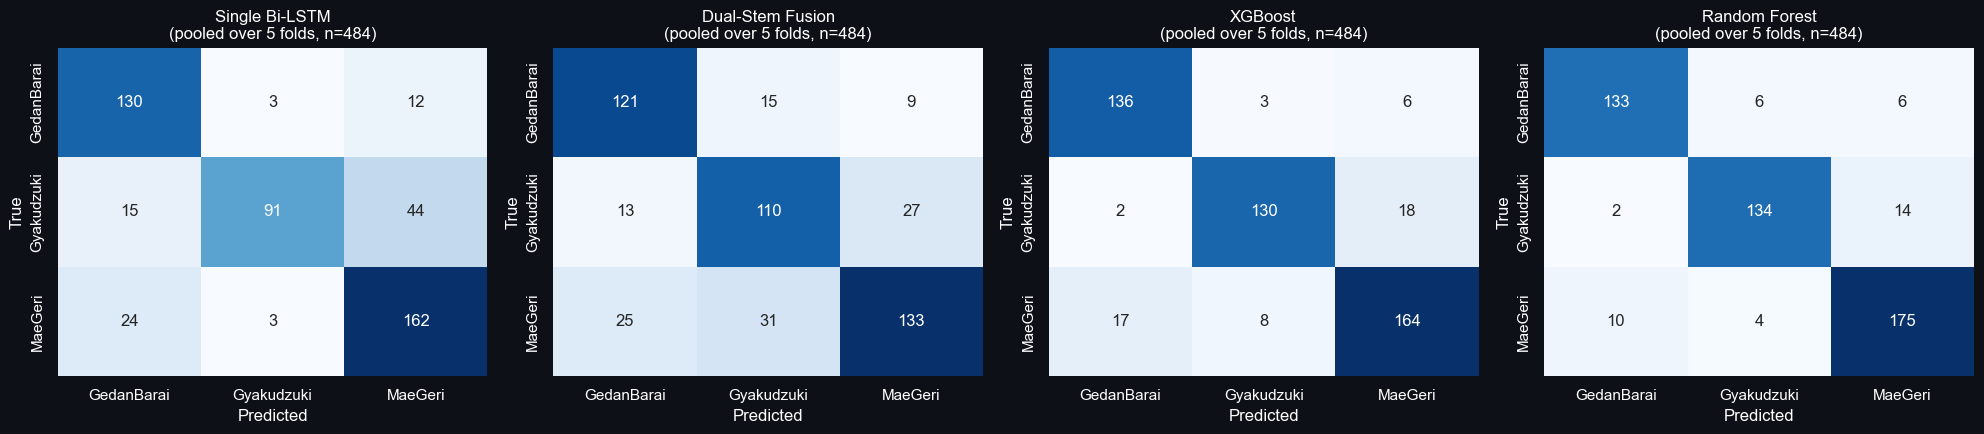


Per-class report, Random Forest (pooled over folds):
              precision    recall  f1-score   support

  GedanBarai     0.9172    0.9172    0.9172       145
  Gyakudzuki     0.9306    0.8933    0.9116       150
     MaeGeri     0.8974    0.9259    0.9115       189

    accuracy                         0.9132       484
   macro avg     0.9151    0.9122    0.9134       484
weighted avg     0.9136    0.9132    0.9132       484



In [6]:
# ── §2.3 5-Fold Practitioner-Disjoint CV — all four models ────────────────────
import gc
from itertools import combinations
from sklearn.metrics import f1_score

def _free():
    tf.keras.backend.clear_session(); gc.collect()

def fit_xgb(Xtr, ytr):
    """Default XGBoost (identical to the numbers first reported). If the allocator fails (bad_malloc on a
    memory-starved Windows kernel) retry once with max_bin=64 and record that fact."""
    for kw in ({}, {'max_bin': 64}):
        try:
            m = XGBClassifier(eval_metric='mlogloss', random_state=RANDOM_SEED, n_jobs=4, **kw)
            m.fit(Xtr, ytr)
            if kw: print("   ⚠️ XGBoost needed the low-memory retry (max_bin=64) — mention this in the paper if it happens in the final run.")
            return m
        except Exception as e:
            print(f"   ⚠️ XGBoost fit failed ({type(e).__name__}: {str(e)[:80]}) → freeing memory"); _free()
    raise RuntimeError("XGBoost failed twice — restart the kernel / enlarge the page file.")

def fit_rf(Xtr, ytr):
    m = RandomForestClassifier(n_estimators=200, random_state=RANDOM_SEED, n_jobs=4)
    m.fit(Xtr, ytr); return m

gkf = GroupKFold(n_splits=5)
X_ids   = meta_df['clip_id'].values
y_ids   = meta_df['label_enc'].values
groups  = meta_df['practitioner_id'].values

MODELS = ['Single Bi-LSTM', 'Dual-Stem Fusion', 'XGBoost', 'Random Forest']
fold_acc = {k: [] for k in MODELS}
fold_f1  = {k: [] for k in MODELS}
pooled   = {k: {'y': [], 'p': []} for k in MODELS}
fold_details = []

def _record(name, y_true, y_pred):
    fold_acc[name].append(accuracy_score(y_true, y_pred))
    fold_f1[name].append(f1_score(y_true, y_pred, average='macro'))
    pooled[name]['y'] += list(y_true); pooled[name]['p'] += list(y_pred)

for fold, (tr_i, te_i) in enumerate(gkf.split(X_ids, y_ids, groups), 1):
    tr_clips, te_clips = X_ids[tr_i], X_ids[te_i]
    tr_prac,  te_prac  = set(groups[tr_i]), set(groups[te_i])
    assert not (tr_prac & te_prac), f"LEAKAGE in fold {fold}!"

    Xf_tr, Xu_tr, Xl_tr, y_tr = build_sequences(tr_clips)
    Xf_te, Xu_te, Xl_te, y_te = build_sequences(te_clips)
    print(f"\n{'='*80}\n🥊 FOLD {fold} | LEAKAGE OVERLAP: {tr_prac & te_prac} ✅ | "
          f"train {len(tr_clips)} clips/{len(tr_prac)} pracs | test {len(te_clips)} clips/{len(te_prac)} pracs")

    # ---- tree models FIRST (cheap, and memory is still free) ----
    _free()
    Xtr_flat = np.ascontiguousarray(Xf_tr.reshape(len(Xf_tr), -1), dtype=np.float32)
    Xte_flat = np.ascontiguousarray(Xf_te.reshape(len(Xf_te), -1), dtype=np.float32)
    xgb = fit_xgb(Xtr_flat, y_tr);  _record('XGBoost', y_te, xgb.predict(Xte_flat)); del xgb
    rf  = fit_rf(Xtr_flat, y_tr);   _record('Random Forest', y_te, rf.predict(Xte_flat)); del rf
    del Xtr_flat, Xte_flat; gc.collect()

    # ---- neural models: early stopping uses a practitioner-disjoint VALIDATION split of the training fold ----
    yt_tr = to_categorical(y_tr, N_CLASSES)
    fit_clips, val_clips = carve_val(tr_clips)
    Xf_fit, Xu_fit, Xl_fit, y_fit = build_sequences(fit_clips)
    Xf_val, Xu_val, Xl_val, y_val = build_sequences(val_clips)
    yt_fit = to_categorical(y_fit, N_CLASSES); yt_val = to_categorical(y_val, N_CLASSES)
    es = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

    m1 = build_single_bilstm(n_feats=len(FULL_FEATS), n_classes=N_CLASSES)
    m1.fit(Xf_fit, yt_fit, validation_data=(Xf_val, yt_val), epochs=100, batch_size=32, callbacks=[es], verbose=0)
    _record('Single Bi-LSTM', y_te, m1.predict(Xf_te, verbose=0).argmax(1))

    m2 = build_dual_stem_model(n_upper=len(UPPER_FEATS), n_lower=len(LOWER_FEATS), n_classes=N_CLASSES)
    m2.fit([Xu_fit, Xl_fit], yt_fit, validation_data=([Xu_val, Xl_val], yt_val), epochs=100, batch_size=32, callbacks=[es], verbose=0)
    _record('Dual-Stem Fusion', y_te, m2.predict([Xu_te, Xl_te], verbose=0).argmax(1))

    del m1, m2; _free()
    fold_details.append({'fold': fold, 'n_test': len(te_clips), 'test_practitioners': sorted(te_prac),
                         **{f'{k} acc': round(fold_acc[k][-1]*100, 2) for k in MODELS}})
    print("   fold acc %:", {k: round(fold_acc[k][-1]*100, 2) for k in MODELS})

def _table(d):
    t = pd.DataFrame({k: [v*100 for v in vals] for k, vals in d.items()}).T
    t.columns = [f"Fold {i}" for i in range(1, 6)]
    t['Mean ± Std'] = [f"{r.mean():.2f} ± {r.std(ddof=1):.2f}" for _, r in t.iterrows()]
    return t

cv_table = _table(fold_acc); cv_f1_table = _table(fold_f1)
print("\n🏆 5-FOLD PRACTITIONER-DISJOINT CV — accuracy (%)"); display(cv_table)
print("\n🏆 5-FOLD PRACTITIONER-DISJOINT CV — macro-F1 (%)"); display(cv_f1_table)

# ---- all pairwise paired t-tests across folds, Holm-corrected (n = 5 folds → very low power; say so) ----
pairs = list(combinations(MODELS, 2)); raw = []
for a, b in pairs:
    t, p = ttest_rel(fold_acc[a], fold_acc[b])
    raw.append({'A': a, 'B': b, 'mean diff A-B (pts)': round((np.mean(fold_acc[a])-np.mean(fold_acc[b]))*100, 2),
                'folds A>B': int(sum(x > y for x, y in zip(fold_acc[a], fold_acc[b]))), 't': round(float(t), 3), 'p_raw': float(p)})
order = np.argsort([r['p_raw'] for r in raw]); m = len(raw); run_max = 0.0
for rank, idx in enumerate(order):
    adj = min(1.0, (m - rank) * raw[idx]['p_raw']); run_max = max(run_max, adj); raw[idx]['p_holm'] = round(run_max, 4)
for r in raw: r['p_raw'] = round(r['p_raw'], 4)
pair_df = pd.DataFrame(raw); print("\nPairwise paired t-tests (accuracy across the 5 folds):"); display(pair_df)

# keep the names used by the summary cell
t_stat, p_val = ttest_rel(fold_acc['Dual-Stem Fusion'], fold_acc['Single Bi-LSTM'])
print(f"\nDual-Stem vs Single Bi-LSTM: t={t_stat:.3f}, p={p_val:.4f}  "
      + ("→ significant at α=0.05" if p_val < 0.05 else "→ NOT significant (n=5 folds: low power)"))

# ---- pooled confusion matrices (every test clip appears exactly once across the 5 folds) ----
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, k in zip(axes, MODELS):
    cmk = confusion_matrix(pooled[k]['y'], pooled[k]['p'])
    sns.heatmap(cmk, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(f"{k}\n(pooled over 5 folds, n={len(pooled[k]['y'])})"); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.tight_layout(); fig.savefig(RESULTS_DIR/'cv_pooled_confusions.png', dpi=150, facecolor=fig.get_facecolor()); plt.show()
print("\nPer-class report, Random Forest (pooled over folds):")
print(classification_report(pooled['Random Forest']['y'], pooled['Random Forest']['p'], target_names=CLASS_NAMES, digits=4))

pd.DataFrame(fold_details).to_csv(RESULTS_DIR/'cv_fold_membership.csv', index=False)
cv_table.to_csv(RESULTS_DIR/'cv_results.csv'); cv_f1_table.to_csv(RESULTS_DIR/'cv_results_macro_f1.csv')
pair_df.to_csv(RESULTS_DIR/'cv_pairwise_tests.csv', index=False)


Golden run: fit 368 clips | val 19 clips | test 97 clips

Golden split — Dual-Stem accuracy : 84.54%  (82/97 clips)
Golden split — Single accuracy    : 87.63%

=== Dual-Stem classification report (golden test set) ===
              precision    recall  f1-score   support

  GedanBarai     0.9211    0.7609    0.8333        46
  Gyakudzuki     0.6667    0.7500    0.7059        16
     MaeGeri     0.8537    1.0000    0.9211        35

    accuracy                         0.8454        97
   macro avg     0.8138    0.8370    0.8201        97
weighted avg     0.8548    0.8454    0.8440        97



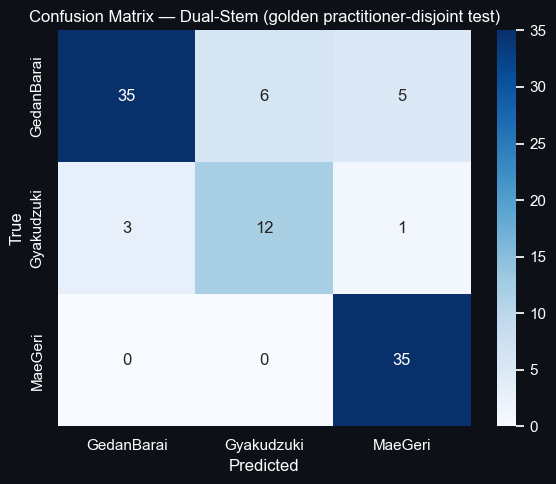


=== GOLDEN SPLIT — all four models ===


,model,accuracy %,macro-F1 %,correct/total
0,Dual-Stem Fusion,84.54,82.01,82/97
1,Single Bi-LSTM,87.63,83.69,85/97
2,XGBoost,88.66,86.71,86/97
3,Random Forest,84.54,78.44,82/97



=== Random Forest classification report (golden test set) ===
              precision    recall  f1-score   support

  GedanBarai     1.0000    0.8478    0.9176        46
  Gyakudzuki     0.6667    0.5000    0.5714        16
     MaeGeri     0.7609    1.0000    0.8642        35

    accuracy                         0.8454        97
   macro avg     0.8092    0.7826    0.7844        97
weighted avg     0.8587    0.8454    0.8413        97



In [7]:
# ── §2.4 Golden hold-out run (train on 43 practitioners, test on 12) ─────────
# NOTE: this is a hand-picked split. Lead with the 5-fold CV (§2.3) in the paper; report this as a secondary split.
Xf_tr, Xu_tr, Xl_tr, y_tr = build_sequences(train_clips)
Xf_te, Xu_te, Xl_te, y_te = build_sequences(test_clips)
yt_tr = to_categorical(y_tr, N_CLASSES); yt_te = to_categorical(y_te, N_CLASSES)

# FIX 2: validation split from TRAIN practitioners only (test set untouched until the final evaluation)
fit_clips, val_clips = carve_val(train_clips)
Xf_fit, Xu_fit, Xl_fit, y_fit = build_sequences(fit_clips)
Xf_val, Xu_val, Xl_val, y_val = build_sequences(val_clips)
yt_fit = to_categorical(y_fit, N_CLASSES); yt_val = to_categorical(y_val, N_CLASSES)
print(f"Golden run: fit {len(fit_clips)} clips | val {len(val_clips)} clips | test {len(test_clips)} clips")
es = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
dual_golden = build_dual_stem_model(n_upper=len(UPPER_FEATS), n_lower=len(LOWER_FEATS), n_classes=N_CLASSES)
dual_golden.fit([Xu_fit, Xl_fit], yt_fit, validation_data=([Xu_val, Xl_val], yt_val),
                epochs=150, batch_size=32, callbacks=[es], verbose=0)
single_golden = build_single_bilstm(n_feats=len(FULL_FEATS), n_classes=N_CLASSES)
single_golden.fit(Xf_fit, yt_fit, validation_data=(Xf_val, yt_val),
                  epochs=100, batch_size=16, callbacks=[es], verbose=0)

probs_dual   = dual_golden.predict([Xu_te, Xl_te], verbose=0)
probs_single = single_golden.predict(Xf_te, verbose=0)
pred_dual    = probs_dual.argmax(1)

print(f"\nGolden split — Dual-Stem accuracy : {accuracy_score(y_te, pred_dual)*100:.2f}%  "
      f"({int(accuracy_score(y_te,pred_dual)*len(y_te))}/{len(y_te)} clips)")
print(f"Golden split — Single accuracy    : {accuracy_score(y_te, probs_single.argmax(1))*100:.2f}%")
print("\n=== Dual-Stem classification report (golden test set) ===")
print(classification_report(y_te, pred_dual, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_te, pred_dual)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
ax.set_title('Confusion Matrix — Dual-Stem (golden practitioner-disjoint test)'); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.tight_layout(); fig.savefig(RESULTS_DIR/'confusion_golden.png', dpi=150, facecolor=fig.get_facecolor()); plt.show()

# keep models + tensors for §4/§5
TEST_CLIP_IDS = list(pd.Series(test_clips))       # clip order used by build_sequences? see §4 note
np.savez(RESULTS_DIR/'golden_test_tensors.npz', Xf=Xf_te, Xu=Xu_te, Xl=Xl_te, y=y_te,
         clip_ids=np.array(sorted(df[df['clip_id'].isin(test_clips)]['clip_id'].unique())))
dual_golden.save(RESULTS_DIR/'best_dual_stem_fusion.keras')
single_golden.save(RESULTS_DIR/'best_single_bilstm.keras')


# ── golden split for the two tree models (fills the "---" cells of the paper's golden-vs-CV table) ──
_free()
Xtr_flat = np.ascontiguousarray(Xf_tr.reshape(len(Xf_tr), -1), dtype=np.float32)
Xte_flat = np.ascontiguousarray(Xf_te.reshape(len(Xf_te), -1), dtype=np.float32)
xgb_golden = fit_xgb(Xtr_flat, y_tr)
rf_golden  = fit_rf(Xtr_flat, y_tr)
probs_rf   = rf_golden.predict_proba(Xte_flat); probs_xgb = xgb_golden.predict_proba(Xte_flat)
golden_rows = []
for name, pr in (('Dual-Stem Fusion', probs_dual), ('Single Bi-LSTM', probs_single),
                 ('XGBoost', probs_xgb), ('Random Forest', probs_rf)):
    pred = pr.argmax(1)
    golden_rows.append({'model': name, 'accuracy %': round(accuracy_score(y_te, pred)*100, 2),
                        'macro-F1 %': round(f1_score(y_te, pred, average='macro')*100, 2),
                        'correct/total': f"{int((pred == y_te).sum())}/{len(y_te)}"})
golden_df = pd.DataFrame(golden_rows); print("\n=== GOLDEN SPLIT — all four models ==="); display(golden_df)
golden_df.to_csv(RESULTS_DIR/'golden_all_models.csv', index=False)
print("\n=== Random Forest classification report (golden test set) ===")
print(classification_report(y_te, probs_rf.argmax(1), target_names=CLASS_NAMES, digits=4))


## §3 — Extract the NEW Master Ground Truth (isolated textbook techniques)
Replaces the MADS **Bassai Dai** GT (biomechanically mismatched — it is a kata performance, not isolated techniques).

**Expected video names:** `<Move>_<stance>.mp4` → `MaeGeri_standing.mp4`, `GyakuZuki_zenkutsu.mp4`, … (3 moves × 2 stances × 3 reps = 18 clips).
Pipeline: MediaPipe Pose → 9 joint angles (identical triplets to `dtw_comparator.compute_mads_angles`) → **Savitzky-Golay (window=5)** → downsample to 30 frames → average reps per (move, stance) → automatic right-limb-dominant orientation.
Output keys: `mae_geri_from_standing`, `mae_geri_from_zenkutsu`, etc. → saved to `backend/app/rag/data/master_reference_sequences.json`.


In [8]:
# ── §3.1 MediaPipe extraction of the Master GT videos (self-contained) ────────
import mediapipe as mp
import cv2

MASTER_ANGLE_NAMES = ["right_elbow","left_elbow","right_shoulder","left_shoulder",
                      "right_knee","left_knee","right_hip","left_hip","spine_lean"]
MOVE_MAP    = {"maegeri":"mae_geri", "gyakudzuki":"gyaku_zuki", "gedanbarai":"gedan_barai"}
GT_OUT_PATH = Path("../rag/data/master_reference_sequences.json")   # backend/app/rag/data/...

def _angle3d(lms, i, j, k):
    ba = lms[i] - lms[j]; bc = lms[k] - lms[j]
    nb, nc = np.linalg.norm(ba), np.linalg.norm(bc)
    if nb == 0 or nc == 0: return 0.0
    return float(np.degrees(np.arccos(np.clip(np.dot(ba, bc)/(nb*nc+1e-8), -1, 1))))

def frame_angles_9(lms):        # same triplets as dtw_comparator.compute_mads_angles
    return [_angle3d(lms,12,14,16), _angle3d(lms,11,13,15),
            _angle3d(lms,14,12,24), _angle3d(lms,13,11,23),
            _angle3d(lms,24,26,28), _angle3d(lms,23,25,27),
            _angle3d(lms,12,24,26), _angle3d(lms,11,23,25),
            _angle3d(lms, 0,23,25)]

def parse_master_name(stem):
    parts = stem.split('_')
    move = MOVE_MAP.get(re.sub(r'[^a-z]', '', parts[0].lower()))
    tail = '_'.join(p.lower() for p in parts[1:])
    stance = 'standing' if 'standing' in tail else ('zenkutsu' if 'zenkutsu' in tail else None)
    return move, stance

def video_angles(path):
    pose = mp.solutions.pose.Pose(static_image_mode=False, model_complexity=1,
                                  min_detection_confidence=0.5, min_tracking_confidence=0.5)
    cap = cv2.VideoCapture(str(path)); rows = []
    while True:
        ok, fr = cap.read()
        if not ok: break
        res = pose.process(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
        if res.pose_landmarks:
            lms = np.array([[l.x, l.y, l.z] for l in res.pose_landmarks.landmark], np.float32)
            rows.append(frame_angles_9(lms))
    cap.release(); pose.close()
    return np.array(rows, np.float32)

def smooth_downsample(ang, w=5):
    if len(ang) >= w: ang = savgol_filter(ang, window_length=w, polyorder=2, axis=0)
    idx = np.linspace(0, len(ang)-1, SEQ_LEN).astype(int)
    return ang[idx]

grouped = {}
for vf in sorted(Path(MASTER_GT_DIR).glob("*")):
    if vf.suffix.lower() not in (".mp4",".mov",".avi",".mkv"): continue
    move, stance = parse_master_name(vf.stem)
    if not move or not stance:
        print(f"⚠️ skipped {vf.name} (name must be <Move>_<stance>)"); continue
    print(f"▶ {vf.name} → {move}_from_{stance}")
    grouped.setdefault((move, stance), []).append(smooth_downsample(video_angles(vf)))

MIRROR_PAIRS = [(0,1),(2,3),(4,5),(6,7)]
def flip(m):
    m = m.copy()
    for a,b in MIRROR_PAIRS: m[...,a], m[...,b] = m[...,b].copy(), m[...,a].copy()
    return m
def limb_dyn(mat):   # dynamic range of knee/hip joints → dominant limb detection
    return float(np.mean(mat[...,4:8].max(-2) - mat[...,4:8].min(-2)))

master_gt = {}
for (move, stance), reps in sorted(grouped.items()):
    stack = np.stack(reps)                          # (R,30,9)
    if limb_dyn(flip(stack)) > limb_dyn(stack): stack = flip(stack)
    key = f"{move}_from_{stance}"
    master_gt[key] = {"fps": 30.0, "angle_names": MASTER_ANGLE_NAMES, "n_frames": SEQ_LEN,
                      "angles": np.round(stack.mean(0), 2).tolist()}
    print(f"✅ {key}: averaged {len(reps)} rep(s)")

missing = {f"{m}_from_{s}" for m in MOVE_MAP.values() for s in ("standing","zenkutsu")} - set(master_gt)
if missing: print("⚠️ Missing GT keys:", sorted(missing))
GT_OUT_PATH.write_text(json.dumps(master_gt, indent=2), encoding="utf-8")
print(f"💾 Wrote {len(master_gt)} GT sequences → {GT_OUT_PATH}")


▶ GedanBarai_standing_side_048_0001.mov → gedan_barai_from_standing
▶ Gyakudzuki_standing_side_050_0001.mov → gyaku_zuki_from_standing
▶ MaeGeri_zenkutsu_side_048_0001.mov → mae_geri_from_zenkutsu
✅ gedan_barai_from_standing: averaged 1 rep(s)
✅ gyaku_zuki_from_standing: averaged 1 rep(s)
✅ mae_geri_from_zenkutsu: averaged 1 rep(s)
⚠️ Missing GT keys: ['gedan_barai_from_zenkutsu', 'gyaku_zuki_from_zenkutsu', 'mae_geri_from_standing']
💾 Wrote 3 GT sequences → ..\rag\data\master_reference_sequences.json


## §4 — Classify the 9 Held-Out Trainee Videos (all models)
Videos named like **`GedanBarai_side_048_0002.mp4`** (`<Move>_<view>_<practitioner>_<clip>`). Each video is run through MediaPipe → 30-frame window → every model from §2. Ground-truth label comes from the filename prefix (these are the 3 practitioners × 3 moves recorded at the Academy).


In [9]:
# ── §4.1 Video → 102-feature tensor (exact replica of the app's feature_extractor) ──
sys.path.insert(0, str(Path.cwd().parent.parent))          # backend/ so `app` is importable
from app.rag.feature_extractor import extract_102_features

ANGLE_IDX_9 = None   # kept for DTW section
MOVE_MAP = {
    "maegeri": "mae_geri",
    "gyakuzuki": "gyaku_zuki",
    "gyakudzuki": "gyaku_zuki",  # Added to handle the 'd' spelling
    "gedanbarai": "gedan_barai"
}


def video_landmark_frames(path):
    """Returns list of frames; each frame = list of 33 dicts {x,y,z,visibility}."""
    pose = mp.solutions.pose.Pose(static_image_mode=False, model_complexity=1,
                                  min_detection_confidence=0.5, min_tracking_confidence=0.5)
    cap = cv2.VideoCapture(str(path)); frames = []
    while True:
        ok, fr = cap.read()
        if not ok: break
        res = pose.process(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
        if res.pose_landmarks:
            frames.append([{'x': l.x, 'y': l.y, 'z': l.z, 'visibility': l.visibility}
                           for l in res.pose_landmarks.landmark])
    cap.release(); pose.close()
    return frames

def clip_to_tensors(frames):
    """30-frame linspace window → X_full (1,30,102), plus upper/lower split, + raw dict frames."""
    idx = np.linspace(0, len(frames)-1, SEQ_LEN).astype(int)
    sel = [frames[i] for i in idx]
    feats = np.stack([extract_102_features(f) for f in sel])          # (30,102)
    return (feats[None, :, :],
            feats[None, :, :54], feats[None, :, 54:],
            sel)

def parse_trainee_name(stem):
    p = stem.split('_')
    move_raw = MOVE_MAP.get(re.sub(r'[^a-z]', '', p[0].lower()))
    label_display = {'mae_geri':'MaeGeri', 'gyaku_zuki':'Gyakudzuki', 'gedan_barai':'GedanBarai'}.get(move_raw)
    
    # robustly find the practitioner ID (the first numeric block, usually 3 digits)
    prac = next((part for part in p if part.isdigit() and len(part) >= 2), '?')
    
    if prac != '?': prac = prac.zfill(3)      # FIX: '50' -> '050' so IDs match the dataset convention
    stance = 'zenkutsu' if 'zenkutsu' in stem.lower() else 'standing'
    return label_display, prac, stance

    
trainee_records = []
for vf in sorted(Path(TRAINEE_VID_DIR).glob("*")):
    if vf.suffix.lower() not in (".mp4", ".mov", ".avi"): continue
    gt_label, prac, stance = parse_trainee_name(vf.stem)
    if gt_label is None:
        print(f"⚠️ Unrecognized name: {vf.name}"); continue
    frames = video_landmark_frames(vf)
    if len(frames) < SEQ_LEN:
        print(f"⚠️ Too few detected frames ({len(frames)}) in {vf.name}"); continue
    Xf, Xu, Xl, sel = clip_to_tensors(frames)
    trainee_records.append({'video': vf.name, 'gt_label': gt_label, 'practitioner': prac,
                            'stance': stance, 'Xf': Xf, 'Xu': Xu, 'Xl': Xl, 'frames': sel})
    print(f"▶ {vf.name}: {len(frames)} raw frames → 30-frame tensor ✅")

print(f"\n{len(trainee_records)} trainee clips loaded")
_tp = {r['practitioner'] for r in trainee_records}
_inuse = _tp & (set(meta_df['practitioner_id']))
print("🛡️ Trainee practitioners present in train/test/CV data:", _inuse if _inuse else "none ✅ (truly held out)")
_kinds = {r['video']: ('001-correct' if Path(r['video']).stem.endswith('001') else '002-faulty' if Path(r['video']).stem.endswith('002') else '?') for r in trainee_records}
print("Clip kinds:", pd.Series(_kinds).value_counts().to_dict())


▶ GedanBarai_side_048_001.mov: 45 raw frames → 30-frame tensor ✅
▶ GedanBarai_side_048_002.mov: 36 raw frames → 30-frame tensor ✅
▶ GedanBarai_side_049_001.mov: 41 raw frames → 30-frame tensor ✅
▶ GedanBarai_side_049_002.mov: 41 raw frames → 30-frame tensor ✅
▶ GedanBarai_side_050_001.mov: 69 raw frames → 30-frame tensor ✅
▶ Gyakudzuki_side_048_002.mov: 32 raw frames → 30-frame tensor ✅
▶ Gyakudzuki_side_050_002.mov: 63 raw frames → 30-frame tensor ✅
▶ Gyakudzuki_side_50_001.mov: 60 raw frames → 30-frame tensor ✅
▶ Maegeri_zenkutsu_side_048_001.mov: 65 raw frames → 30-frame tensor ✅
▶ MaeGeri_zenkutsu_side_048_002.mov: 56 raw frames → 30-frame tensor ✅
▶ MaeGeri_zenkutsu_side_051_002.mov: 71 raw frames → 30-frame tensor ✅

11 trainee clips loaded
🛡️ Trainee practitioners present in train/test/CV data: none ✅ (truly held out)
Clip kinds: {'002-faulty': 6, '001-correct': 5}


##### videos in the trainee dir with vid number 001 (ex. ) are moves performed correctly as possible 
##### videos in the trainee dir with vid number 002 (ex. MaeGeri_zenkutsu_side_051_002.mov) are moves performed with purposely doing (a) specefic mistake(s) in the move  

In [10]:
# ── §4.2 Run all models on the trainee videos ───────────────────────────────
label_to_enc = {name: i for i, name in enumerate(CLASS_NAMES)}
rows = []
for rec in trainee_records:
    y_true = label_to_enc[rec['gt_label']]
    pd_dual   = dual_golden.predict([rec['Xu'], rec['Xl']], verbose=0)[0]
    pd_single = single_golden.predict(rec['Xf'], verbose=0)[0]
    flat      = rec['Xf'].reshape(1, -1)
    p_xgb     = xgb_golden.predict_proba(flat.astype(np.float32))[0]
    p_rf      = rf_golden.predict_proba(flat.astype(np.float32))[0]
    
    rows.append({
        'video': rec['video'], 'gt': rec['gt_label'], 'prac': rec['practitioner'],
        'Dual→pred': CLASS_NAMES[pd_dual.argmax()], 'Dual conf': round(float(pd_dual.max()), 3),
        'Dual margin': round(float(np.sort(pd_dual)[-1] - np.sort(pd_dual)[-2]), 3),
        'Single→pred': CLASS_NAMES[pd_single.argmax()], 'Single conf': round(float(pd_single.max()), 3),
        
        # INSERTED LINE HERE:
        'Single margin': round(float(np.sort(pd_single)[-1]-np.sort(pd_single)[-2]), 3),
        
        'XGB→pred': CLASS_NAMES[p_xgb.argmax()], 'XGB conf': round(float(p_xgb.max()), 3),
        'RF→pred': CLASS_NAMES[p_rf.argmax()], 'RF conf': round(float(p_rf.max()), 3),
        'correct_dual': pd_dual.argmax() == y_true, 'correct_single': pd_single.argmax() == y_true,
        'correct_xgb': p_xgb.argmax() == y_true, 'correct_rf': p_rf.argmax() == y_true,
        '_probs_dual': pd_dual,
    })

res_df = pd.DataFrame(rows).drop(columns=['_probs_dual'])
display(res_df)
acc_d = res_df['correct_dual'].mean()*100; acc_s = res_df['correct_single'].mean()*100
acc_x = res_df['correct_xgb'].mean()*100; acc_r = res_df['correct_rf'].mean()*100
print(f"\nTrainee set ({len(res_df)} clips) — Dual-Stem: {acc_d:.1f}% | Single Bi-LSTM: {acc_s:.1f}% | XGBoost: {acc_x:.1f}% | Random Forest: {acc_r:.1f}%")
res_df.to_csv(RESULTS_DIR/'trainee9_classification.csv', index=False)

,video,gt,prac,Dual→pred,Dual conf,Dual margin,Single→pred,Single conf,Single margin,XGB→pred,XGB conf,RF→pred,RF conf,correct_dual,correct_single,correct_xgb,correct_rf
0,GedanBarai_side_048_001.mov,GedanBarai,048,GedanBarai,0.998,0.997,GedanBarai,0.993,0.987,GedanBarai,0.937,GedanBarai,0.670,True,True,True,True
1,GedanBarai_side_048_002.mov,GedanBarai,048,GedanBarai,0.999,0.998,GedanBarai,0.994,0.989,GedanBarai,0.863,GedanBarai,0.560,True,True,True,True
2,GedanBarai_side_049_001.mov,GedanBarai,049,GedanBarai,0.990,0.980,GedanBarai,0.967,0.936,GedanBarai,0.942,GedanBarai,0.735,True,True,True,True
3,GedanBarai_side_049_002.mov,GedanBarai,049,GedanBarai,0.968,0.937,GedanBarai,0.970,0.941,Gyakudzuki,0.895,MaeGeri,0.385,True,True,False,False
4,GedanBarai_side_050_001.mov,GedanBarai,050,GedanBarai,0.989,0.979,GedanBarai,0.943,0.911,GedanBarai,0.908,GedanBarai,0.515,True,True,True,True
5,Gyakudzuki_side_048_002.mov,Gyakudzuki,048,Gyakudzuki,0.999,0.999,Gyakudzuki,0.996,0.994,Gyakudzuki,0.917,Gyakudzuki,0.530,True,True,True,True
6,Gyakudzuki_side_050_002.mov,Gyakudzuki,050,GedanBarai,0.920,0.842,Gyakudzuki,0.958,0.936,GedanBarai,0.971,GedanBarai,0.605,False,True,False,False
7,Gyakudzuki_side_50_001.mov,Gyakudzuki,050,GedanBarai,0.989,0.982,Gyakudzuki,0.986,0.976,GedanBarai,0.676,GedanBarai,0.445,False,True,False,False
8,Maegeri_zenkutsu_side_048_001.mov,MaeGeri,048,MaeGeri,0.999,0.999,GedanBarai,0.665,0.334,MaeGeri,0.988,MaeGeri,0.545,True,False,True,True
9,MaeGeri_zenkutsu_side_048_002.mov,MaeGeri,048,MaeGeri,0.934,0.869,MaeGeri,0.593,0.188,MaeGeri,0.921,MaeGeri,0.515,True,True,True,True



Trainee set (11 clips) — Dual-Stem: 81.8% | Single Bi-LSTM: 81.8% | XGBoost: 72.7% | Random Forest: 72.7%


## §5 — OOD Cascade: FPR + FRR + ROC/AUROC (Reviewer C's core demand)
Three layers exactly like `routers/classify.py` + `ood_config.py`:
1. **Softmax confidence** `P_max < τ₁`
2. **Top-2 margin** `Δ < τ₂`
3. **DTW validation** `min-class DTW distance > τ₃` (against the new Master GT)

* **FPR** = distractors accepted as karate. * **FRR** = valid karate rejected.
* **In-distribution:** the 9 Academy trainee clips (+ optionally golden CSV test clips via their tensors).
* **Distractors:** put any non-karate clips (walking/sitting/waving/other martial arts from NTU-style exports, or your lab recordings) into `DISTRACTOR_VID_DIR`. If empty, §5 runs FRR-only and prints a warning.


In [11]:
# ── §5.0 Config + local DTW (identical math to dtw_comparator._dtw_distance) ──
DISTRACTOR_VID_DIR = r"D:\CS-Senior26'\GR\Karate_phase\Distractors"      # non-karate clips
CONF_THR, MARGIN_THR, DTW_THR = 0.65, 0.15, 35.0         # ood_config.py defaults

def _dtw_path(a, b):
    n, m = len(a), len(b)
    D = np.full((n+1, m+1), np.inf); D[0,0] = 0
    cost = np.abs(a[:,None,:] - b[None,:,:]).sum(-1)     # (n,m,k) L1 over joints
    for i in range(1, n+1):
        for j in range(1, m+1):
            D[i,j] = cost[i-1,j-1] + min(D[i-1,j], D[i,j-1], D[i-1,j-1])
    return D[n,m] / min(n, m)

def mirror9(seq):
    s = seq.copy()
    for a,b in [(0,1),(2,3),(4,5),(6,7)]: s[:,a], s[:,b] = seq[:,b].copy(), seq[:,a].copy()
    return s

def dtw_scores_9(user_frames_dict, gt_dict):
    """user_frames_dict: list of 33-dict frames → per-class min(original, mirrored) DTW distance."""
    user = np.array([frame_angles_9(np.array([[l['x'],l['y'],l['z']] for l in f]))
                     for f in user_frames_dict], np.float32)
    mir  = mirror9(user)
    scores = {}
    for key, meta in gt_dict.items():
        if '__rep' in key: continue
        ref = np.array(meta['angles'], np.float32)
        base = key.split('_from_')[0]                    # collapse stance variants by move
        d = min(_dtw_path(user, ref), _dtw_path(mir, ref))
        scores[base] = min(scores.get(base, np.inf), d)
    return scores

# gather OOD features for every in-distribution clip
ood_records = []
for rec in trainee_records:
    probs = dual_golden.predict([rec['Xu'], rec['Xl']], verbose=0)[0]
    ps = single_golden.predict(rec['Xf'], verbose=0)[0]; s_sorted = np.sort(ps)[::-1]
    p_sorted = np.sort(probs)[::-1]
    dists = dtw_scores_9(rec['frames'], master_gt)
    ood_records.append({'video': rec['video'], 'kind': 'karate',
                        'pmax': float(p_sorted[0]), 'margin': float(p_sorted[0]-p_sorted[1]),
                        'pmax_s': float(s_sorted[0]), 'margin_s': float(s_sorted[0]-s_sorted[1]),
                        'dtw_min': float(min(dists.values()))})

# UPDATE 1: Change the glob to "*" and check if the generator yields anything valid
def has_valid_videos(dir_path):
    for vf in Path(dir_path).glob("*"):
        if vf.suffix.lower() in (".mp4", ".mov", ".avi"): return True
    return False

dist_present = Path(DISTRACTOR_VID_DIR).is_dir() and has_valid_videos(DISTRACTOR_VID_DIR)

if dist_present:
    # UPDATE 2: Change glob to "*"
    for vf in sorted(Path(DISTRACTOR_VID_DIR).glob("*")):
        # UPDATE 3: Check suffixes
        if vf.suffix.lower() not in (".mp4", ".mov", ".avi"): continue
        
        frames = video_landmark_frames(vf)
        if len(frames) < SEQ_LEN: continue
        idx = np.linspace(0, len(frames)-1, SEQ_LEN).astype(int)
        sel = [frames[i] for i in idx]
        feats = np.stack([extract_102_features(f) for f in sel])[None]
        probs = dual_golden.predict([feats[:, :, :54], feats[:, :, 54:]], verbose=0)[0]
        ps = single_golden.predict(feats, verbose=0)[0]; s_sorted = np.sort(ps)[::-1]
        p_sorted = np.sort(probs)[::-1]
        dists = dtw_scores_9(sel, master_gt)
        ood_records.append({'video': vf.name, 'kind': 'distractor',
                            'pmax': float(p_sorted[0]), 'margin': float(p_sorted[0]-p_sorted[1]),
                            'pmax_s': float(s_sorted[0]), 'margin_s': float(s_sorted[0]-s_sorted[1]),
                        'dtw_min': float(min(dists.values()))})
else:
    print("⚠️ No distractor videos found — FPR/ROC will use karate-only scores (fill DISTRACTOR_VID_DIR to complete Fig. 3).")

ood_df = pd.DataFrame(ood_records)
ood_df['label'] = (ood_df['kind'] == 'karate').astype(int)   # 1 = should be ACCEPTED
display(ood_df.round(3))

,video,kind,pmax,margin,pmax_s,margin_s,dtw_min,label
0,GedanBarai_side_048_001.mov,karate,0.998,0.997,0.993,0.987,18.928,1
1,GedanBarai_side_048_002.mov,karate,0.999,0.998,0.994,0.989,105.424,1
2,GedanBarai_side_049_001.mov,karate,0.990,0.980,0.967,0.936,197.135,1
3,GedanBarai_side_049_002.mov,karate,0.968,0.937,0.970,0.941,221.482,1
4,GedanBarai_side_050_001.mov,karate,0.989,0.979,0.943,0.911,126.622,1
5,Gyakudzuki_side_048_002.mov,karate,0.999,0.999,0.996,0.994,230.196,1
6,Gyakudzuki_side_050_002.mov,karate,0.920,0.842,0.958,0.936,206.465,1
7,Gyakudzuki_side_50_001.mov,karate,0.989,0.982,0.986,0.976,21.890,1
8,Maegeri_zenkutsu_side_048_001.mov,karate,0.999,0.999,0.665,0.334,13.654,1
9,MaeGeri_zenkutsu_side_048_002.mov,karate,0.934,0.869,0.593,0.188,156.627,1


In [12]:
# ── §5.1 Cascade at production thresholds → FPR & FRR per layer ───────────────
def cascade(df, conf_thr, margin_thr, dtw_thr, pcol='pmax', mcol='margin'):
    acc_l1 = df[pcol]    >= conf_thr
    acc_l2 = acc_l1 & (df[mcol] >= margin_thr)
    acc_l3 = acc_l2 & (df['dtw_min'] <= dtw_thr)
    out = {}
    
    for name, mask in [('L1 softmax', acc_l1), ('L2 margin', acc_l2), ('L3 DTW', acc_l3), ('Cascade', acc_l3)]:
        # Filter the mask series directly using the DataFrame's label column
        mask_k = mask[df['label'] == 1]  # Karate clips
        mask_d = mask[df['label'] == 0]  # Distractor clips
        
        frr = 1 - mask_k.mean() if len(mask_k) > 0 else np.nan          # valid karate rejected
        fpr = mask_d.mean() if len(mask_d) > 0 else np.nan              # distractors accepted
        
        out[name] = {'FRR %': round(float(frr)*100,1) if frr==frr else None,
                     'FPR %': round(float(fpr)*100,1) if fpr==fpr else None}
    return pd.DataFrame(out).T

print(f"At production thresholds τ₁={CONF_THR}, τ₂={MARGIN_THR}, τ₃={DTW_THR}°:")
print("Dual-Stem softmax signals:")
display(cascade(ood_df, CONF_THR, MARGIN_THR, DTW_THR, 'pmax', 'margin'))
print("Single Bi-LSTM softmax signals (same DTW layer):")
display(cascade(ood_df, CONF_THR, MARGIN_THR, DTW_THR, 'pmax_s', 'margin_s'))

At production thresholds τ₁=0.65, τ₂=0.15, τ₃=35.0°:
Dual-Stem softmax signals:


,FRR %,FPR %
L1 softmax,0.0,85.7
L2 margin,0.0,85.7
L3 DTW,72.7,0.0
Cascade,72.7,0.0


Single Bi-LSTM softmax signals (same DTW layer):


,FRR %,FPR %
L1 softmax,9.1,85.7
L2 margin,9.1,85.7
L3 DTW,72.7,0.0
Cascade,72.7,0.0


Softmax P_max (Dual): AUROC = 0.6753
Top-2 Margin (Dual): AUROC = 0.6753
Softmax P_max (Single): AUROC = 0.1688
Top-2 Margin (Single): AUROC = 0.1558
DTW distance: AUROC = 0.9091
Combined (Dual): AUROC = 0.9091
Combined (Single): AUROC = 0.7273


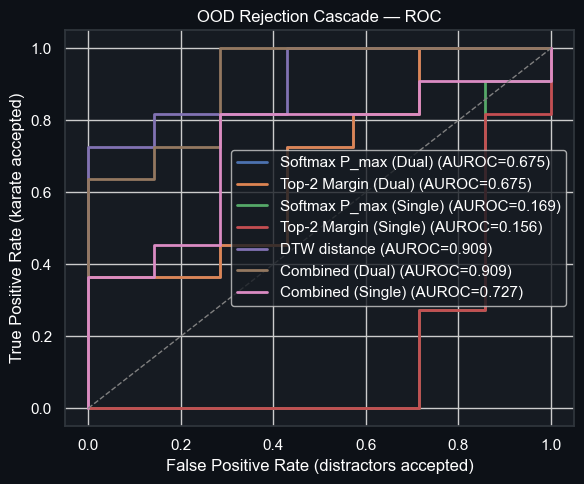

In [13]:
# ── §5.2 ROC curves + AUROC per score (and combined cascade score) ────────────
if not dist_present:
    print("⚠️ Skipping ROC — need distractor clips.")
else:
    # Combined acceptability score: normalize each signal to [0,1] where higher=more karate-like
    def norm(s, invert=False):
        v = (s - s.min()) / (s.max() - s.min() + 1e-9)
        return 1 - v if invert else v
    scores = {
        'Softmax P_max (Dual)':  ood_df['pmax'],
        'Top-2 Margin (Dual)':   ood_df['margin'],
        'Softmax P_max (Single)': ood_df['pmax_s'],
        'Top-2 Margin (Single)':  ood_df['margin_s'],
        'DTW distance':   ood_df['dtw_min'],           # lower = more karate-like
        'Combined (Dual)': norm(ood_df['pmax']) * norm(ood_df['margin']) * norm(ood_df['dtw_min'], invert=True),
        'Combined (Single)': norm(ood_df['pmax_s']) * norm(ood_df['margin_s']) * norm(ood_df['dtw_min'], invert=True),
    }
    y = ood_df['label'].values
    fig, ax = plt.subplots(figsize=(6,5))
    for name, sc in scores.items():
        s = sc.values.astype(float)
        if name == 'DTW distance':                      # threshold on high distance = reject
            fpr, tpr, _ = roc_curve(y, -s)
        else:
            fpr, tpr, _ = roc_curve(y, s)
        au = auc(fpr, tpr)
        ax.plot(fpr, tpr, lw=2, label=f'{name} (AUROC={au:.3f})')
        print(f"{name}: AUROC = {au:.4f}")
    ax.plot([0,1],[0,1],'--', color='gray', lw=1)
    ax.set_xlabel('False Positive Rate (distractors accepted)')
    ax.set_ylabel('True Positive Rate (karate accepted)')
    ax.set_title('OOD Rejection Cascade — ROC')
    ax.legend(); plt.tight_layout()
    fig.savefig(RESULTS_DIR/'ood_roc.png', dpi=150, facecolor=fig.get_facecolor()); plt.show()
    ood_df.to_csv(RESULTS_DIR/'ood_scores.csv', index=False)


In [14]:
# ── §5.3 Calibration / overconfidence — computed from the actual outputs (both models) ──
def conf_table(name, probs, y_true):
    p = np.asarray(probs); pred = p.argmax(1); conf = p.max(1); ok = pred == np.asarray(y_true)
    return {'set': name, 'n': len(y_true),
            'mean conf (correct)': round(float(conf[ok].mean()), 3) if ok.any() else None,
            'mean conf (wrong)':   round(float(conf[~ok].mean()), 3) if (~ok).any() else None,
            'n wrong': int((~ok).sum())}
rows = [dict(model='Dual-Stem', **conf_table('golden test', probs_dual, y_te)),
        dict(model='Single',    **conf_table('golden test', probs_single, y_te))]
ood_k = ood_df[ood_df['kind']=='karate']; ood_d = ood_df[ood_df['kind']=='distractor']
rows += [dict(model='Dual-Stem', set='distractors', n=len(ood_d), **{'mean conf (correct)': None, 'mean conf (wrong)': round(float(ood_d['pmax'].mean()),3) if len(ood_d) else None, 'n wrong': None}),
         dict(model='Single',    set='distractors', n=len(ood_d), **{'mean conf (correct)': None, 'mean conf (wrong)': round(float(ood_d['pmax_s'].mean()),3) if len(ood_d) else None, 'n wrong': None})]
calib_df = pd.DataFrame(rows); display(calib_df)
calib_df.to_csv(RESULTS_DIR/'calibration_overconfidence.csv', index=False)
print("Read this honestly: if 'mean conf (wrong)' is close to 'mean conf (correct)' (and distractor confidence is high), "
      "softmax confidence cannot separate good from bad inputs — which is why DTW (layer 3) carries the OOD rejection.")


,model,set,n,mean conf (correct),mean conf (wrong),n wrong
0,Dual-Stem,golden test,97,0.971,0.817,15.0
1,Single,golden test,97,0.966,0.746,12.0
2,Dual-Stem,distractors,7,NaN,0.916,NaN
3,Single,distractors,7,NaN,0.948,NaN


Read this honestly: if 'mean conf (wrong)' is close to 'mean conf (correct)' (and distractor confidence is high), softmax confidence cannot separate good from bad inputs — which is why DTW (layer 3) carries the OOD rejection.


## §6 — DTW Feedback Replication (peak deviation, mirroring, mean-vs-max proof)
Replicates `compare_with_dtw` against the **new Master GT** with **stance routing**: `MaeGeri_*_standing` compares against `mae_geri_from_standing`, zenkutsu clips against `mae_geri_from_zenkutsu`. Also produces **Fig. 2 material**: the angle trajectory plot proving why mean error hides peak faults.



▶ GedanBarai_side_048_001.mov (standing GT):
   ✅ within tolerance on all 9 joints

▶ GedanBarai_side_048_002.mov (standing GT):
   • spine_lean: 25.8° off — user 112.7° vs master 87.4° (too extended/large)
   • right_knee: 22.6° off — user 123.7° vs master 146.1° (too bent/small)
   • left_knee: 22.6° off — user 113.1° vs master 91.7° (too extended/large)
   • left_shoulder: 20.8° off — user 65.6° vs master 45.5° (too extended/large)

▶ GedanBarai_side_049_001.mov (standing GT):
   • spine_lean: 92.5° off — user 79.9° vs master 178.8° (too bent/small)
   • right_elbow: 77.0° off — user 168.9° vs master 90.9° (too extended/large)
   • left_shoulder: 71.2° off — user 81.6° vs master 7.7° (too extended/large)
   • left_hip: 67.2° off — user 82.3° vs master 156.2° (too bent/small)

▶ GedanBarai_side_049_002.mov (standing GT):
   • right_elbow: 65.2° off — user 161.8° vs master 96.6° (too extended/large)
   • left_knee: 45.9° off — user 119.2° vs master 165.1° (too bent/small)
   • left_s

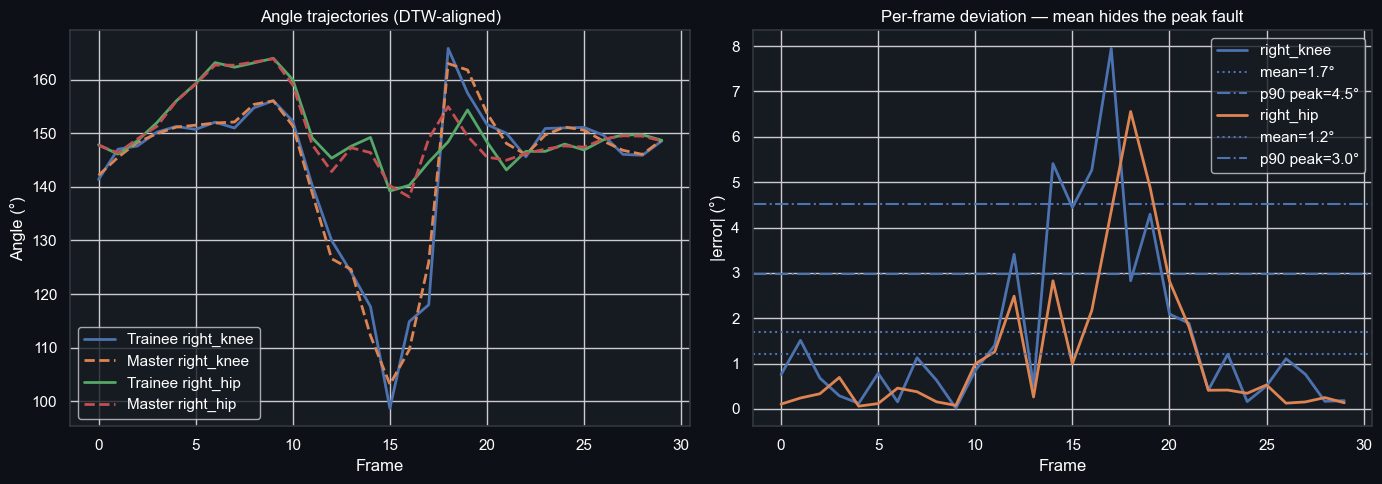

In [15]:
# ── §6.1 compare_with_dtw replica + mean-vs-max proof plot ────────────────────
ERROR_THRESHOLD = 12.0

def dtw_align(a, b):
    n, m = len(a), len(b)
    D = np.full((n+1, m+1), np.inf); D[0,0] = 0
    cost = np.abs(a[:,None,:] - b[None,:,:]).sum(-1)
    P = np.zeros((n+1, m+1))
    for i in range(1, n+1):
        for j in range(1, m+1):
            opts = [D[i-1,j], D[i,j-1], D[i-1,j-1]]
            D[i,j] = cost[i-1,j-1] + min(opts)
            P[i,j] = int(np.argmin(opts))
    path, i, j = [], n, m
    while i > 0 and j > 0:
        path.append((i-1, j-1))
        k = P[i,j]
        i, j = (i-1, j) if k==0 else (i, j-1) if k==1 else (i-1, j-1)
    return path[::-1]

def feedback_errors(rec):
    move = {'MaeGeri':'mae_geri','Gyakudzuki':'gyaku_zuki','GedanBarai':'gedan_barai'}[rec['gt_label']]
    key  = f"{move}_from_{rec['stance']}"
    # BUGFIX: master_gt only contains the stance variants actually extracted from the
    # exemplar videos (e.g. mae_geri_from_zenkutsu). A trainee clip whose parsed stance
    # has no matching GT key used to raise KeyError here, aborting §6 and leaving
    # all_feedback stale/empty for the §7 feedback arms. Fall back to any variant of
    # the same technique.
    if key not in master_gt:
        _cands = [k for k in master_gt if k.startswith(move + "_from_")]
        if _cands:
            print(f"\u26a0\ufe0f no GT for '{key}' \u2014 using '{_cands[0]}'")
            key = _cands[0]
    ref  = np.array(master_gt[key]['angles'], np.float32)
    user = np.array([frame_angles_9(np.array([[l['x'],l['y'],l['z']] for l in f]))
                     for f in rec['frames']], np.float32)
    mir  = mirror9(user)
    d_o, d_m = _dtw_path(user, ref), _dtw_path(mir, ref)
    best = mir if d_m < d_o else user
    path = dtw_align(best, ref)
    ua = best[[p[0] for p in path]]; ra = ref[[p[1] for p in path]]
    diff = np.abs(ua - ra)
    peak = np.percentile(diff, 90, axis=0)                    # app uses p90 "peak deviation"
    errs = []
    for k, joint in enumerate(MASTER_ANGLE_NAMES):
        if peak[k] >= ERROR_THRESHOLD:
            ui = int(np.argmin(np.abs(diff[:,k] - peak[k])))
            errs.append({'joint': joint, 'mean_error': round(float(peak[k]),1),
                         'user_val': round(float(ua[ui,k]),1), 'ref_val': round(float(ra[ui,k]),1),
                         'direction': 'too extended/large' if ua[ui,k] > ra[ui,k] else 'too bent/small'})
    return sorted(errs, key=lambda e: e['mean_error'], reverse=True), user, ref, diff

all_feedback = {}
for rec in trainee_records:
    errs, u, r, diff = feedback_errors(rec)
    all_feedback[rec['video']] = errs
    print(f"\n▶ {rec['video']} ({rec['stance']} GT):")
    for e in errs[:4]:
        print(f"   • {e['joint']}: {e['mean_error']}° off — user {e['user_val']}° vs master {e['ref_val']}° ({e['direction']})")
    if not errs: print("   ✅ within tolerance on all 9 joints")

# Fig.2-style proof: mean error hides peak faults
vid = trainee_records[0]['video']; rec = trainee_records[0]
_, u, r, diff = feedback_errors(rec)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for j in [4, 6]:   # right_knee, right_hip
    axes[0].plot(u[:, j], lw=2, label=f'Trainee {MASTER_ANGLE_NAMES[j]}')
    axes[0].plot(r[:, j], lw=2, ls='--', label=f'Master {MASTER_ANGLE_NAMES[j]}')
axes[0].set_title('Angle trajectories (DTW-aligned)'); axes[0].set_xlabel('Frame'); axes[0].set_ylabel('Angle (°)'); axes[0].legend()
for j in [4, 6]:
    axes[1].plot(diff[:, j], lw=2, label=MASTER_ANGLE_NAMES[j])
    axes[1].axhline(diff[:, j].mean(), ls=':', label=f'mean={diff[:,j].mean():.1f}°')
    axes[1].axhline(np.percentile(diff[:, j], 90), ls='-.', label=f'p90 peak={np.percentile(diff[:,j],90):.1f}°')
axes[1].set_title('Per-frame deviation — mean hides the peak fault'); axes[1].set_xlabel('Frame'); axes[1].set_ylabel('|error| (°)'); axes[1].legend()
plt.tight_layout(); fig.savefig(RESULTS_DIR/'mean_vs_max_proof.png', dpi=150, facecolor=fig.get_facecolor()); plt.show()


In [16]:
# ── §6.2 Seeded-fault evaluation: does DTW feedback catch the mistake the trainee made on purpose? ──
# <move>_<view>_<prac>_001 = performed as correctly as possible  → should produce (almost) NO flagged joints
# <move>_<view>_<prac>_002 = purposely wrong                      → flagged joints should include the intended fault(s)
# Fill INTENDED_FAULTS with the joints that each *_002 clip was *meant* to get wrong, using names from MASTER_ANGLE_NAMES
# (right/left_elbow, right/left_shoulder, right/left_knee, right/left_hip, spine_lean).
INTENDED_FAULTS = {
    # 'Maegeri_side_052_002.mov': ['right_knee'],
    # 'Gyakudzuki_side_050_002.mov': ['right_shoulder', 'spine_lean'],
}
TOP_K = 3
def _kind(v):
    st = Path(v).stem
    return 'correct(001)' if st.endswith('001') else 'faulty(002)' if st.endswith('002') else 'other'

rows = []
for rec in trainee_records:
    errs = all_feedback[rec['video']]; flagged = [e['joint'] for e in errs]
    row = {'video': rec['video'], 'kind': _kind(rec['video']), 'n_flagged': len(flagged), 'top_flagged': flagged[:TOP_K]}
    intended = INTENDED_FAULTS.get(rec['video'])
    if intended:
        topk = set(flagged[:TOP_K]); row['intended'] = intended
        row['hit@1'] = bool(flagged and flagged[0] in intended)
        row['recall@k'] = round(len(topk & set(intended)) / len(intended), 2)
    rows.append(row)
fault_df = pd.DataFrame(rows); display(fault_df)

good = fault_df[fault_df['kind']=='correct(001)']
bad  = fault_df[fault_df['kind']=='faulty(002)']
if len(good): print(f"001 (correct) clips: mean flagged joints = {good['n_flagged'].mean():.2f}; "
                    f"clips with ≥1 false alarm = {(good['n_flagged']>0).sum()}/{len(good)}")
if len(bad):  print(f"002 (faulty) clips : mean flagged joints = {bad['n_flagged'].mean():.2f}")
if 'hit@1' in fault_df and fault_df['hit@1'].notna().any():
    sc = fault_df.dropna(subset=['hit@1'])
    print(f"Seeded-fault detection over {len(sc)} labelled clips: hit@1 = {sc['hit@1'].mean()*100:.1f}% | mean recall@{TOP_K} = {sc['recall@k'].mean()*100:.1f}%")
else:
    print("⚠️ INTENDED_FAULTS is empty — fill it to get hit@1 / recall@k (this is the quantitative evidence for the feedback claim).")
fault_df.to_csv(RESULTS_DIR/'seeded_fault_eval.csv', index=False)


,video,kind,n_flagged,top_flagged
0,GedanBarai_side_048_001.mov,correct(001),0,[]
1,GedanBarai_side_048_002.mov,faulty(002),8,"[spine_lean, right_knee, left_knee]"
2,GedanBarai_side_049_001.mov,correct(001),9,"[spine_lean, right_elbow, left_shoulder]"
3,GedanBarai_side_049_002.mov,faulty(002),9,"[right_elbow, left_knee, left_shoulder]"
4,GedanBarai_side_050_001.mov,correct(001),9,"[right_elbow, right_shoulder, right_knee]"
5,Gyakudzuki_side_048_002.mov,faulty(002),9,"[right_hip, left_shoulder, spine_lean]"
6,Gyakudzuki_side_050_002.mov,faulty(002),9,"[left_knee, left_hip, right_elbow]"
7,Gyakudzuki_side_50_001.mov,correct(001),0,[]
8,Maegeri_zenkutsu_side_048_001.mov,correct(001),0,[]
9,MaeGeri_zenkutsu_side_048_002.mov,faulty(002),9,"[spine_lean, left_hip, left_knee]"


001 (correct) clips: mean flagged joints = 3.60; clips with ≥1 false alarm = 2/5
002 (faulty) clips : mean flagged joints = 8.83
⚠️ INTENDED_FAULTS is empty — fill it to get hit@1 / recall@k (this is the quantitative evidence for the feedback claim).


## §7 — Feedback Quality Ablation (Reviewer A's demand)

Three arms on the DTW errors of every trainee clip: **Rule template**, **Direct LLM** (no retrieval) and **RAG+LLM** (retrieved coaching chunks).

**Robustness note.** Retrieval no longer depends on `torch`/`sentence-transformers` (which crashed with `WinError 1114` on this machine). `safe_retrieve()` tries the app's ChromaDB retriever, then the same MiniLM model via ONNX, then TF-IDF; the mode actually used and the number of live vs. offline LLM calls are printed at the end of the cell and must be quoted in the paper. The cell also computes the automatic checks promised in the paper (joint coverage, no degree values) and saves `feedback_ablation.csv`, `feedback_ablation_full.json` and `feedback_ablation_checks.csv`.

In [17]:
# ── §7.1 Three feedback arms (Rule template / Direct LLM / RAG+LLM) — robust, torch-free ─────────────
# ROOT CAUSE of the old crash (OSError WinError 1114, c10.dll):
#   app.rag.retriever.retrieve() builds a SentenceTransformerEmbeddingFunction on its first CALL,
#   which imports sentence_transformers -> torch -> c10.dll. On this Windows env torch cannot load,
#   and because the failure happened at call time (not import time) the old try/except around the
#   *import* never caught it, so the whole cell died.
# FIX: retrieval now goes through safe_retrieve(), a 3-level chain that never raises:
#   1) the app's ChromaDB retriever (only if torch can really be imported)
#   2) the SAME embedding model (all-MiniLM-L6-v2) run via ONNX runtime (no torch) over coaching_chunks.json
#   3) TF-IDF cosine similarity over coaching_chunks.json (pure scikit-learn)
# The mode that was actually used is recorded, so the paper never reports a fallback as full RAG.
import os as _os, sys, re, json, time, importlib
from pathlib import Path as _P
import numpy as np

# ── locate backend/ ───────────────────────────────────────────────────────────
try:
    _BACKEND_DIR                                     # defined in §4.1
except NameError:
    def _find_backend_dir():
        seeds = []
        if globals().get('BACKEND_DIR'): seeds.append(_P(globals()['BACKEND_DIR']))
        try: seeds.append(_P(globals()['__vsc_ipynb_file__']))
        except KeyError: pass
        seeds.append(_P.cwd())
        seen, roots = set(), []
        for s in seeds:
            for p in ([s.resolve()] + list(s.resolve().parents)):
                if str(p) not in seen: seen.add(str(p)); roots.append(p)
        marker = _P('app') / 'rag' / 'feature_extractor.py'
        for r in roots:
            for cand in (r, r / 'backend', r / '..' / 'backend'):
                if (cand / marker).is_file(): return cand.resolve()
        return None
    _BACKEND_DIR = _find_backend_dir()
if _BACKEND_DIR is None:
    raise RuntimeError("Could not auto-locate backend/. Set BACKEND_DIR = r'C:\\path\\to\\repo\\backend' first.")
if str(_BACKEND_DIR) not in sys.path: sys.path.insert(0, str(_BACKEND_DIR))
print(f"📦 backend/ located at {_BACKEND_DIR}")

# ── .env (GROQ_API_KEY) must be loaded BEFORE llm_client is imported ─────────
try:
    from dotenv import load_dotenv
    for _f in (_BACKEND_DIR / '.env', _P.cwd() / '.env', _P.cwd() / '..' / '.env'):
        if _f.is_file(): load_dotenv(str(_f), override=False)
except Exception as _e:
    print(f"[§7] dotenv not available ({_e}) — relying on process environment.")

# ── coaching knowledge base (same JSON the app seeds ChromaDB from) ───────────
_CHUNKS = []
for _jp in list(_BACKEND_DIR.rglob('coaching_chunks.json')) or list(_BACKEND_DIR.rglob('*chunk*.json')):
    try:
        _d = json.load(open(_jp, encoding='utf-8'))
        _CHUNKS = [c for c in (_d if isinstance(_d, list) else _d.get('chunks', [])) if isinstance(c, dict) and c.get('text')]
        if _CHUNKS: break
    except Exception:
        continue
print(f"📚 coaching chunks loaded: {len(_CHUNKS)}")

MOVE_KEY = {'GedanBarai': 'gedan_barai', 'Gyakudzuki': 'gyaku_zuki', 'MaeGeri': 'mae_geri'}   # label -> chunk 'move'
def _move_key(m):
    m = str(m)
    return MOVE_KEY.get(m, re.sub(r'[\s\-]+', '_', re.sub(r'(?<=[a-z])(?=[A-Z])', '_', m)).lower())
def _joint_family(j):                                 # right_knee -> knee ; spine_lean -> stance
    j = str(j).replace('left_', '').replace('right_', '')
    return {'spine_lean': 'stance'}.get(j, j)

# ── retrieval back-ends ───────────────────────────────────────────────────────
RETRIEVER_MODE = None           # 'chromadb' | 'onnx-minilm' | 'tfidf' | 'none'
_emb = {'ef': None, 'M': None}
_tfidf = {'vec': None, 'M': None}
_chroma_retrieve = None
USE_APP_CHROMA = False   # True = try the app's ChromaDB+sentence-transformers retriever (needs torch). Keep False in this
                         # TensorFlow kernel: torch+TF in one Windows process is what raised WinError 1114.
try:
    if not USE_APP_CHROMA: raise ImportError('USE_APP_CHROMA=False → torch-free ONNX MiniLM retrieval over coaching_chunks.json')
    import torch
    from app.rag.retriever import retrieve as _chroma_retrieve
    RETRIEVER_MODE = 'chromadb'
except BaseException as _e:                          # OSError / ImportError / anything
    print(f"⚠️ ChromaDB+torch retriever unavailable ({type(_e).__name__}: {str(_e)[:90]}) → torch-free fallback.")

def _chunk_text(c):
    return f"{c.get('move','')} {c.get('joint','')} {c.get('error_type','')} {c.get('topic','')}. {c['text']}"

def _init_onnx():
    from chromadb.utils.embedding_functions import ONNXMiniLM_L6_V2      # same all-MiniLM-L6-v2 weights, ONNX runtime, no torch
    ef = ONNXMiniLM_L6_V2()
    M = np.asarray(ef([_chunk_text(c) for c in _CHUNKS]), dtype=np.float32)
    M /= (np.linalg.norm(M, axis=1, keepdims=True) + 1e-9)
    _emb['ef'], _emb['M'] = ef, M

def _init_tfidf():
    from sklearn.feature_extraction.text import TfidfVectorizer
    vec = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), sublinear_tf=True)
    _tfidf['M'] = vec.fit_transform([_chunk_text(c) for c in _CHUNKS]); _tfidf['vec'] = vec

def _rank(query, move_k, joint_f, top_k):
    global RETRIEVER_MODE
    if not _CHUNKS: return []
    sims = None
    if RETRIEVER_MODE in (None, 'onnx-minilm'):
        try:
            if _emb['M'] is None: _init_onnx()
            q = np.asarray(_emb['ef']([query]), dtype=np.float32)[0]; q /= (np.linalg.norm(q) + 1e-9)
            sims = _emb['M'] @ q; RETRIEVER_MODE = 'onnx-minilm'
        except BaseException as _e:
            if RETRIEVER_MODE != 'tfidf': print(f"⚠️ ONNX embeddings unavailable ({type(_e).__name__}: {str(_e)[:80]}) → TF-IDF.")
            RETRIEVER_MODE = 'tfidf'
    if sims is None:
        try:
            if _tfidf['M'] is None: _init_tfidf()
            sims = (_tfidf['M'] @ _tfidf['vec'].transform([query]).T).toarray().ravel(); RETRIEVER_MODE = 'tfidf'
        except BaseException as _e:
            print(f"⚠️ TF-IDF retrieval failed ({type(_e).__name__}: {_e}) → no retrieval."); RETRIEVER_MODE = 'none'; return []
    bonus = np.array([(0.5 if c.get('move') == move_k else -1.0) +
                      (0.15 if joint_f and c.get('joint') == joint_f else 0.0) +
                      (0.0 if c.get('error_type') != 'none' else -0.05) for c in _CHUNKS])
    order = np.argsort(-(sims + bonus))
    return [{'text': _CHUNKS[i]['text'], 'metadata': {k: _CHUNKS[i].get(k) for k in ('move', 'joint', 'error_type', 'topic')},
             'score': float(sims[i])} for i in order[:top_k] if _CHUNKS[i].get('move') == move_k]

def safe_retrieve(query, move=None, joint=None, top_k=1):
    """Never raises. Returns a list of {'text','metadata'} dicts (possibly empty)."""
    global RETRIEVER_MODE, _chroma_retrieve
    mk, jf = _move_key(move), _joint_family(joint) if joint else None
    if RETRIEVER_MODE == 'chromadb' and _chroma_retrieve is not None:
        try:
            out = _chroma_retrieve(query, move=mk, top_k=top_k)
            if out: return out
            raise RuntimeError("ChromaDB returned no chunks (collection missing/empty)")
        except BaseException as _e:                  # incl. the torch OSError that used to kill this cell
            print(f"⚠️ ChromaDB retrieval failed at call time ({type(_e).__name__}: {str(_e)[:90]}) → torch-free fallback.")
            RETRIEVER_MODE = None
    return _rank(query, mk, jf, top_k)

# ── LLM client ────────────────────────────────────────────────────────────────
try:
    from app.rag.llm_client import generate_coaching_feedback
    _retired = {"llama-3.1-70b-versatile", "llama-3.3-70b-versatile", "llama3-70b-8192", "llama3-8b-8192", "gemma2-9b-it"}
    _gm = (_os.getenv("GROQ_MODEL") or "").strip()
    if _gm and _gm in _retired: _os.environ.pop("GROQ_MODEL", None)      # never force a decommissioned model
    GROQ_OK = bool(_os.getenv("GROQ_API_KEY"))
except BaseException as _e:
    print(f"⚠️ llm_client import failed ({type(_e).__name__}: {_e}) — LLM arms will use the rule fallback.")
    generate_coaching_feedback = None; GROQ_OK = False

JOINT_FIX = {
 'right_knee': "Extend the driving knee further through the technique's peak moment.",
 'left_knee':  "Check the support-leg knee — keep it stable and aligned.",
 'right_hip':  "Open the hip of the striking leg more at execution.",
 'left_hip':   "Keep the hips level; avoid dropping the support-side hip.",
 'right_elbow':'Tighten the chamber of the striking arm/elbow.',
 'left_elbow': "Control the counter-arm elbow.",
 'right_shoulder':'Drop tension from the striking-side shoulder.',
 'left_shoulder':'Keep the lead shoulder guarded and square.',
 'spine_lean': "Reduce torso lean — stay upright through the technique."}

def map_errors(errors):
    """Same schema as dtw_comparator.compare_with_dtw error_context (llm_client needs 'mean_error')."""
    return [{'joint': e['joint'], 'query': e.get('query') or e['direction'],
             'user_val': e['user_val'], 'ref_val': e['ref_val'], 'mean_error': e['mean_error'],
             'target_range': f"{round(e['ref_val'] - 15):.0f}\u2013{round(e['ref_val'] + 15):.0f}"}   # llm_client appends the ° itself
            for e in errors]

def arm_rule(errors):
    if not errors: return "Clean rep — no joint exceeded the tolerance band."
    return " ".join(f"{e['joint'].replace('_',' ')} is {e['mean_error']}° {e['direction']}. {JOINT_FIX.get(e['joint'],'')}" for e in errors[:3])

_FALLBACK_MARKERS = ("📊 Form analysis", "Looking good! Keep practising")
LLM_STATS = {'live': 0, 'fallback': 0}

def _call_llm(move, errors, chunks):
    """Returns (text, live_flag). Never raises; flags when llm_client silently used its offline formatter."""
    if not GROQ_OK or generate_coaching_feedback is None:
        LLM_STATS['fallback'] += 1; return "[no API key] " + arm_rule(errors), False
    try:
        txt = generate_coaching_feedback(move, map_errors(errors), retrieved_chunks=chunks)
    except BaseException as _e:
        print(f"⚠️ LLM call failed ({type(_e).__name__}: {str(_e)[:100]})")
        LLM_STATS['fallback'] += 1; return "[llm error] " + arm_rule(errors), False
    live = not str(txt).startswith(_FALLBACK_MARKERS)
    LLM_STATS['live' if live else 'fallback'] += 1
    return txt, live

def arm_direct_llm(move, errors):
    return _call_llm(move, errors, [])

def arm_rag_llm(move, errors):
    chunks, seen = [], set()
    for e in errors[:3]:
        for c in safe_retrieve(f"{move} {e['joint'].replace('_',' ')} {e['direction']}", move=move, joint=e['joint'], top_k=1):
            if c['text'] not in seen: seen.add(c['text']); chunks.append(c)
    if not errors: return "Clean rep — no joint exceeded the tolerance band.", None, 0
    if not (GROQ_OK and generate_coaching_feedback):
        grounded = f"[offline RAG evidence] {chunks[0]['text'][:200]}" if chunks else ""
        LLM_STATS['fallback'] += 1
        return arm_rule(errors) + " " + grounded, False, len(chunks)
    txt, live = _call_llm(move, errors, chunks)
    return txt, live, len(chunks)

# ── automatic checks proposed in the paper: (i) mentions flagged joints, (ii) no degree values ──
_JW = {'elbow': ['elbow'], 'shoulder': ['shoulder'], 'knee': ['knee'], 'hip': ['hip', 'pelvis'], 'spine_lean': ['spine', 'torso', 'back', 'posture', 'upright', 'lean', 'chest']}
def _mentions(text, joint):
    t = text.lower(); fam = joint.replace('left_', '').replace('right_', '')
    return any(w in t for w in _JW.get(fam, [fam]))
_DEG = re.compile(r'\d+(\.\d+)?\s*(°|degree|deg\b)|\bdegrees?\b|\bangles?\b', re.I)
def auto_checks(text, errors):
    top = [e['joint'] for e in errors[:3]]
    cov = (sum(_mentions(text, j) for j in top) / len(top)) if top else np.nan
    return {'joint_cov': None if cov != cov else round(float(cov), 2), 'no_degrees': not bool(_DEG.search(text))}

rows = []
for rec in trainee_records:
    errs = all_feedback[rec['video']]; mv = rec['gt_label']
    t_rule = arm_rule(errs)
    t_dir, live_d = arm_direct_llm(mv, errs)
    t_rag, live_r, n_ch = arm_rag_llm(mv, errs)
    row = {'video': rec['video'], 'n_errors': len(errs), 'Rule template': t_rule,
           'Direct LLM': t_dir[:300], 'RAG+LLM (ours)': t_rag[:300],
           'n_chunks': n_ch, 'direct_live': live_d, 'rag_live': live_r}
    for arm, txt in (('rule', t_rule), ('direct', t_dir), ('rag', t_rag)):
        ck = auto_checks(txt, errs)
        row[f'{arm}_joint_cov'] = ck['joint_cov']; row[f'{arm}_no_degrees'] = ck['no_degrees']
    rows.append(row)
ablation_df = pd.DataFrame(rows)
pd.set_option('display.max_colwidth', 60)
display(ablation_df[['video', 'n_errors', 'n_chunks', 'Rule template', 'Direct LLM', 'RAG+LLM (ours)']])
ablation_df.to_csv(RESULTS_DIR / 'feedback_ablation.csv', index=False)

# full (untruncated) texts for the paper appendix / manual rating sheet
with open(RESULTS_DIR / 'feedback_ablation_full.json', 'w', encoding='utf-8') as _fh:
    json.dump(rows, _fh, ensure_ascii=False, indent=1, default=str)

# ── automatic-check summary (flagged clips only; the clean clips have nothing to check) ──
_flagged = ablation_df[ablation_df['n_errors'] > 0]
summ = []
for arm, name in (('rule', 'Rule template'), ('direct', 'Direct LLM'), ('rag', 'RAG+LLM (ours)')):
    summ.append({'arm': name, 'n_clips': len(_flagged),
                 'mean joint coverage': round(float(_flagged[f'{arm}_joint_cov'].astype(float).mean()), 3),
                 'no-degree rate %': round(float(_flagged[f'{arm}_no_degrees'].mean()) * 100, 1)})
abl_summary = pd.DataFrame(summ); display(abl_summary)
abl_summary.to_csv(RESULTS_DIR / 'feedback_ablation_checks.csv', index=False)

print(f"\nRetriever mode used : {RETRIEVER_MODE}   (KB chunks: {len(_CHUNKS)})")
print(f"LLM calls           : live={LLM_STATS['live']} | offline-fallback={LLM_STATS['fallback']}")
if not GROQ_OK:
    print("⚠️ GROQ_API_KEY not set → LLM arms used the offline fallback. Put the key in backend/.env and re-run this cell for live outputs.")
elif LLM_STATS['fallback']:
    print("⚠️ Some LLM calls fell back offline (see the messages above, e.g. a retired model id) — set GROQ_MODEL in backend/.env.")
else:
    print("✅ All LLM arms used live Groq calls.")
if RETRIEVER_MODE != 'chromadb':
    print(f"ℹ️ Arm 3 retrieval used '{RETRIEVER_MODE}' over coaching_chunks.json (not the ChromaDB store). Report it as such in the paper.")


📦 backend/ located at D:\CS-Senior26'\GR\martial-arts-trainer\backend
📚 coaching chunks loaded: 34
⚠️ ChromaDB+torch retriever unavailable (ImportError: USE_APP_CHROMA=False → torch-free ONNX MiniLM retrieval over coaching_chunks.json) → torch-free fallback.
[Metrics] RAG LLM Generation took 3306.67 ms (openai/gpt-oss-20b)
[Metrics] RAG LLM Generation took 1297.61 ms (openai/gpt-oss-20b)
⚠️ ONNX embeddings unavailable (ValueError: The onnxruntime python package is not installed. Please install it with `pip ins) → TF-IDF.
[Metrics] RAG LLM Generation took 779.41 ms (openai/gpt-oss-20b)
[Metrics] RAG LLM Generation took 740.77 ms (openai/gpt-oss-20b)
[Metrics] RAG LLM Generation took 736.03 ms (openai/gpt-oss-20b)
[Metrics] RAG LLM Generation took 1093.38 ms (openai/gpt-oss-20b)
[Metrics] RAG LLM Generation took 1385.40 ms (openai/gpt-oss-20b)
[Metrics] RAG LLM Generation took 818.16 ms (openai/gpt-oss-20b)
[Metrics] RAG LLM Generation took 1715.33 ms (openai/gpt-oss-20b)
[Metrics] RAG L

,video,n_errors,n_chunks,Rule template,Direct LLM,RAG+LLM (ours)
0,GedanBarai_side_048_001.mov,0,0,Clean rep — no joint exceeded the tolerance band.,Great effort on that Gedan‑Barai! I noticed your hands w...,Clean rep — no joint exceeded the tolerance band.
1,GedanBarai_side_048_002.mov,8,2,spine lean is 25.8° too extended/large. Reduce torso lea...,Great effort on the GedanBarai! I noticed a few places w...,Great effort on the Gedan‑Barai! Let’s fine‑tune a few p...
2,GedanBarai_side_049_001.mov,9,3,spine lean is 92.5° too bent/small. Reduce torso lean — ...,Great effort on the Gedan Barai! I noticed a few areas w...,Hey there! I noticed a few things that can help you make...
3,GedanBarai_side_049_002.mov,9,3,right elbow is 65.2° too extended/large. Tighten the cha...,"You’ve got a great start, but let’s tighten a few key sp...",Hey there! I noticed a few spots that could use a little...
4,GedanBarai_side_050_001.mov,9,3,right elbow is 35.5° too bent/small. Tighten the chamber...,Great effort on the Gedan Barai! I noticed a few areas w...,Great effort on the Gedan‑Barai! Let’s fine‑tune a few k...
5,Gyakudzuki_side_048_002.mov,9,3,right hip is 87.8° too extended/large. Open the hip of t...,Great effort on the Gyakudzuki! I noticed that your hips...,Hey there! I see your hips are a bit too wide and your l...
6,Gyakudzuki_side_050_002.mov,9,3,left knee is 56.7° too extended/large. Check the support...,Great effort on the Gyakudzuki! I noticed a few areas wh...,Hey there! I noticed a few places where you can tighten ...
7,Gyakudzuki_side_50_001.mov,0,0,Clean rep — no joint exceeded the tolerance band.,Great effort on the Gyakudzuki! I noticed a couple of th...,Clean rep — no joint exceeded the tolerance band.
8,Maegeri_zenkutsu_side_048_001.mov,0,0,Clean rep — no joint exceeded the tolerance band.,Great effort on your MaeGeri! I noticed a couple of subt...,Clean rep — no joint exceeded the tolerance band.
9,MaeGeri_zenkutsu_side_048_002.mov,9,3,spine lean is 68.6° too extended/large. Reduce torso lea...,Great effort on that Mae Geri! Let’s fine‑tune a few key...,Hey there! I noticed that your spine feels a bit too str...


,arm,n_clips,mean joint coverage,no-degree rate %
0,Rule template,8,1.0,0.0
1,Direct LLM,8,1.0,75.0
2,RAG+LLM (ours),8,1.0,75.0



Retriever mode used : tfidf   (KB chunks: 34)
LLM calls           : live=19 | offline-fallback=0
✅ All LLM arms used live Groq calls.
ℹ️ Arm 3 retrieval used 'tfidf' over coaching_chunks.json (not the ChromaDB store). Report it as such in the paper.


Phase shown: reference frame 17/29 (peak of 'spine_lean' in GedanBarai_side_048_002.mov); user frames a=17, b=12


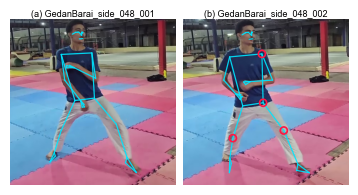


[RAG+LLM text from §7 (same call as in the ablation)]

(a) GedanBarai_side_048_001.mov:
   within tolerance on all 9 joints

(b) GedanBarai_side_048_002.mov:
   • spine_lean: 25.8° off — user 112.7° vs ref 87.4° (too extended/large)
   • right_knee: 22.6° off — user 123.7° vs ref 146.1° (too bent/small)
   • left_knee: 22.6° off — user 113.1° vs ref 91.7° (too extended/large)
   • left_shoulder: 20.8° off — user 65.6° vs ref 45.5° (too extended/large)

flagged joints: (a) 0/9, (b) 8/9
System text excerpt typeset under (b):
Great effort on the Gedan‑Barai! Let’s fine‑tune a few points so the block feels more
balanced and powerful. ...

💾 Saved → Results\master_validation\fig_trainee.png and Results\master_validation\trainee_feedback.tex  (copy both into the paper's figs/ folder)


In [18]:
# ── §7.2 Qualitative figure for the paper (Fig. "trainee"): reference clip vs. deliberate-fault clip ──
# One single-column figure: two frames side by side (a: *_001 correct, b: *_002 deliberate fault).
# The DTW lines + system text are typeset under it by the paper (figs/trainee_feedback.tex holds the system text).
# Both frames show the SAME PHASE of the technique: the reference frame where the top flagged joint of the
# faulty clip deviates most (its p90 "peak" moment); each clip contributes the user frame aligned to it by DTW.
# NOTE: for 048, clip *_001 IS the reference recording, so panel (a) is clean by construction (say so in the caption).
#       To show an independent practitioner instead (e.g. '049', which exposes a false alarm), change FIG_PRAC only;
#       the paper's caption/paragraph then has to be edited accordingly.
import textwrap
FIG_PRAC, FIG_MOVE = '048', 'GedanBarai'
LLM_EXCERPT_CHARS  = 150          # keep the typeset text short so the figure stays small
FIG_W_IN, FIG_H_IN = 3.45, 1.85   # IEEE single column ≈ 3.5 in

_by_name = {r['video']: r for r in trainee_records}
def _find(suffix):
    c = [r for r in trainee_records if r['practitioner'] == FIG_PRAC and r['gt_label'] == FIG_MOVE
         and Path(r['video']).stem.endswith(suffix)]
    if not c: raise RuntimeError(f"No {FIG_MOVE} clip of practitioner {FIG_PRAC} with suffix {suffix} in trainee_records")
    return c[0]
rec_a, rec_b = _find('001'), _find('002')            # a = correct / reference, b = deliberate fault

# ── DTW path (same logic as feedback_errors, but we also keep the alignment) ──
def _aligned(rec):
    errs, user, ref, diff = feedback_errors(rec)
    mir = mirror9(user)
    mirrored = _dtw_path(mir, ref) < _dtw_path(user, ref)
    best = mir if mirrored else user
    path = dtw_align(best, ref)                       # [(user_idx, ref_idx), ...]
    return errs, ref, diff, path, mirrored

errs_a, ref_a, diff_a, path_a, mir_a = _aligned(rec_a)
errs_b, ref_b, diff_b, path_b, mir_b = _aligned(rec_b)
if not errs_b: raise RuntimeError("The faulty clip has no flagged joint, nothing to show.")

top_joint = errs_b[0]['joint']; k = MASTER_ANGLE_NAMES.index(top_joint)
r_b   = int(np.argmax(diff_b[:, k]))                   # path row of the largest deviation in (b)
ref_i = path_b[r_b][1]                                 # reference phase to show
u_b   = path_b[r_b][0]                                 # user frame (0..29) in (b)
cand  = [p[0] for p in path_a if p[1] == ref_i]
u_a   = int(np.median(cand)) if cand else path_a[min(r_b, len(path_a)-1)][0]
print(f"Phase shown: reference frame {ref_i}/{SEQ_LEN-1} (peak of '{top_joint}' in {rec_b['video']}); user frames a={u_a}, b={u_b}")

# ── grab the video frames + landmarks (re-decode; same detected-frame logic as video_landmark_frames) ──
def _frame_and_landmarks(rec, u):
    cap = cv2.VideoCapture(str(Path(TRAINEE_VID_DIR) / rec['video']))
    pose = mp.solutions.pose.Pose(static_image_mode=False, model_complexity=1,
                                  min_detection_confidence=0.5, min_tracking_confidence=0.5)
    det = []                                           # (rgb image, landmarks[33,4]) for frames with a detection
    while True:
        ok, fr = cap.read()
        if not ok: break
        rgb = cv2.cvtColor(fr, cv2.COLOR_BGR2RGB); res = pose.process(rgb)
        if res.pose_landmarks:
            lm = np.array([[l.x, l.y, l.z, l.visibility] for l in res.pose_landmarks.landmark], np.float32)
            det.append((rgb, lm))
    cap.release(); pose.close()
    if len(det) < SEQ_LEN:
        raise RuntimeError(f"{rec['video']}: only {len(det)} frames with a detected pose on re-decode (need ≥ {SEQ_LEN}).")
    sel = np.linspace(0, len(det)-1, SEQ_LEN).astype(int)
    return det[sel[u]]
img_a, lm_a = _frame_and_landmarks(rec_a, u_a)
img_b, lm_b = _frame_and_landmarks(rec_b, u_b)

# ── drawing helpers ──
VERTEX = {'right_elbow':14,'left_elbow':13,'right_shoulder':12,'left_shoulder':11,
          'right_knee':26,'left_knee':25,'right_hip':24,'left_hip':23,'spine_lean':23}
def _flip_lr(name):
    return name.replace('left_','@').replace('right_','left_').replace('@','right_') if name != 'spine_lean' else name
def _square_crop(img, lm, margin=1.18):
    H, W = img.shape[:2]; v = lm[lm[:,3] > 0.3] if (lm[:,3] > 0.3).sum() >= 8 else lm
    x0, x1 = v[:,0].min()*W, v[:,0].max()*W; y0, y1 = v[:,1].min()*H, v[:,1].max()*H
    side = min(max(x1-x0, y1-y0)*margin, min(H, W)); cx, cy = (x0+x1)/2, (y0+y1)/2
    left = int(np.clip(cx-side/2, 0, W-side)); top = int(np.clip(cy-side/2, 0, H-side)); s = int(side)
    return img[top:top+s, left:left+s], (left, top, s, W, H)
def _draw(ax, img, lm, title, flagged=(), mirrored=False):
    crop, (left, top, s, W, H) = _square_crop(img, lm)
    ax.imshow(crop); ax.set_axis_off(); ax.set_xlim(0, s); ax.set_ylim(s, 0)
    for a, b in mp.solutions.pose.POSE_CONNECTIONS:
        if lm[a,3] > 0.3 and lm[b,3] > 0.3:
            ax.plot([lm[a,0]*W-left, lm[b,0]*W-left], [lm[a,1]*H-top, lm[b,1]*H-top], color='#00e5ff', lw=0.9, alpha=.9)
    for j in flagged:                                   # highlight the vertices of the flagged joints
        jj = _flip_lr(j) if mirrored else j
        vi = VERTEX[jj]; ax.scatter([lm[vi,0]*W-left], [lm[vi,1]*H-top], s=26, facecolors='none', edgecolors='#ff1744', linewidths=1.2, zorder=5)
    ax.set_xlim(0, s); ax.set_ylim(s, 0); ax.set_title(title, fontsize=6.5, pad=2)

with plt.rc_context({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'text.color': 'black',
                     'axes.labelcolor': 'black', 'savefig.facecolor': 'white'}):
    fig, axes = plt.subplots(1, 2, figsize=(FIG_W_IN, FIG_H_IN))
    _draw(axes[0], img_a, lm_a, f"(a) {Path(rec_a['video']).stem}")
    _draw(axes[1], img_b, lm_b, f"(b) {Path(rec_b['video']).stem}", flagged=[e['joint'] for e in errs_b[:4]], mirrored=mir_b)
    fig.subplots_adjust(left=0.005, right=0.995, top=0.90, bottom=0.005, wspace=0.03)
    fig.savefig(RESULTS_DIR / 'fig_trainee.png', dpi=300); plt.show()

# ── text typeset under the figure: system (RAG+LLM) output of the faulty clip, shortened ──
def _latex_escape(t):
    for a, b in {'\u2011':'-', '\u2010':'-', '\u2019':"'", '\u2018':"'", '\u201c':'``', '\u201d':"''", '\u2014':'---', '\u2013':'--',
                 '\u00b0':' deg', '\u2026':'...', '\u00a0':' ', '\u202f':' '}.items(): t = t.replace(a, b)
    t = re.sub(r'[^\x00-\x7f]', '', t)                  # drop emoji / non-ASCII
    t = re.sub(r'\*\*?|__', '', t); t = re.sub(r'\s+', ' ', t).strip()
    out = []
    for ch in t:
        out.append({'\\':r'\textbackslash{}','&':r'\&','%':r'\%','$':r'\$','#':r'\#','_':r'\_','{':r'\{','}':r'\}','~':r'\textasciitilde{}','^':r'\^{}'}.get(ch, ch))
    return ''.join(out)
def _shorten(t, n):
    t = re.sub(r'\s+', ' ', str(t)).strip()
    if len(t) <= n: return t
    cut = t[:n]; m = max(cut.rfind('. '), cut.rfind('! '), cut.rfind('? '))
    cut = cut[:m+1] if m > 40 else cut[:cut.rfind(' ')]
    return cut.rstrip(' ,;:') + ' ...'
try:
    sys_text = ablation_df.loc[ablation_df['video'] == rec_b['video'], 'RAG+LLM (ours)'].iloc[0]   # text reported in §7
    src = 'RAG+LLM text from §7 (same call as in the ablation)'
except Exception as _e:
    sys_text = arm_rule(errs_b) if 'arm_rule' in globals() else "(run §7.1 first)"; src = f'rule-template text (§7 not run: {type(_e).__name__})'
excerpt = _shorten(sys_text, LLM_EXCERPT_CHARS)
tex = "\\par\\smallskip\\textit{System text:} ``" + _latex_escape(excerpt) + "''\n"
(RESULTS_DIR / 'trainee_feedback.tex').write_text(tex, encoding='utf-8')

# ── print what the paper must say, straight from the pipeline (compare with the caption in main.tex) ──
print(f"\n[{src}]")
for tag, rc, er in (('(a)', rec_a, errs_a), ('(b)', rec_b, errs_b)):
    print(f"\n{tag} {rc['video']}:")
    if not er: print("   within tolerance on all 9 joints")
    for e in er[:4]:
        print(f"   • {e['joint']}: {e['mean_error']}° off — user {e['user_val']}° vs ref {e['ref_val']}° ({e['direction']})")
print(f"\nflagged joints: (a) {len(errs_a)}/9, (b) {len(errs_b)}/9")
print("System text excerpt typeset under (b):\n" + textwrap.fill(excerpt, 90))
print(f"\n💾 Saved → {RESULTS_DIR/'fig_trainee.png'} and {RESULTS_DIR/'trainee_feedback.tex'}  (copy both into the paper's figs/ folder)")



GedanBarai_side_049_002.mov  |  GT key: GedanBarai/standing  |  mirrored user: False  |  flagged 9/9


,joint,p90 dev (deg),flagged,mean dev (deg),user @peak,GT @peak
0,right_elbow,65.2,True,34.4,154.8,71.7
5,left_knee,45.9,True,18.5,119.2,168.6
3,left_shoulder,41.5,True,20.6,67.6,15.5
4,right_knee,40.6,True,15.4,110.9,156.0
2,right_shoulder,38.8,True,11.2,59.3,12.2
1,left_elbow,34.6,True,21.2,91.6,130.7
8,spine_lean,34.6,True,17.5,70.2,106.8
6,right_hip,33.8,True,13.3,125.4,163.9
7,left_hip,14.5,True,6.1,87.3,110.7


Phase shown: GT frame 29/29, user frame 29/29 (peak of 'right_elbow')


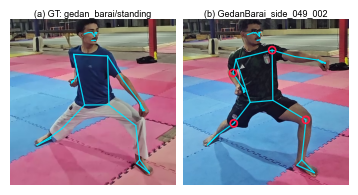

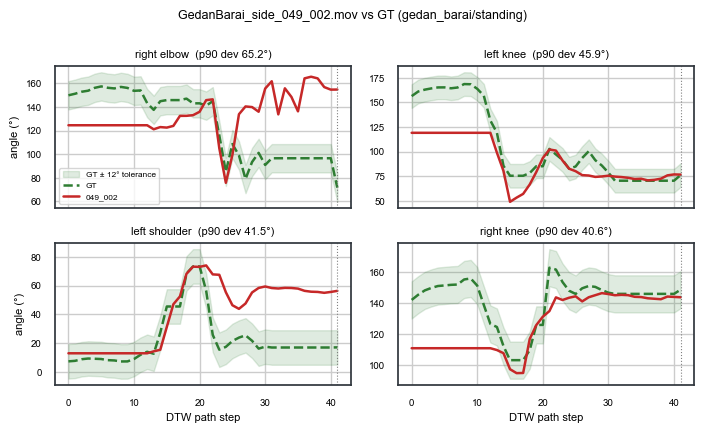


[RAG+LLM text stored by §7.1 (that cell truncates it to 300 chars)]
DTW (user vs GT):
   • right_elbow: 65.2° off — user 161.8° vs GT 96.6° (too extended/large)
   • left_knee: 45.9° off — user 119.2° vs GT 165.1° (too bent/small)
   • left_shoulder: 41.5° off — user 58.5° vs GT 17.0° (too extended/large)
   • right_knee: 40.6° off — user 110.9° vs GT 151.5° (too bent/small)

Text typeset under Fig A (173 chars):
Elbows & Shoulders Your right elbow is a bit too straight, so try letting it bend a
little—imagine a gentle curve in your arm, keeping the forearm almost parallel to the flo

💾 Results\master_validation\gt_vs_049_002_frames.png | Results\master_validation\gt_vs_049_002_curves.png | Results\master_validation\gt_vs_049_002_feedback.tex | Results\master_validation\gt_vs_049_002_joints.csv


In [25]:
# ── §7.3 GT (Master reference) vs 049_002 — frames, angle curves, system text ─────────────────────────
# RUN AFTER §6.1, §7.1 and §7.2 (it re-uses feedback_errors, dtw_align, mirror9, _dtw_path, _draw, VERTEX,
# _mentions, _latex_escape, ablation_df, master_gt, trainee_records).
#
# Produces
#   (1) Fig A  gt_vs_049_002_frames.png   — paper figure: GT frame | 049_002 frame, SAME phase, flagged joints circled
#   (2) Fig B  gt_vs_049_002_curves.png   — analysis figure: user vs GT angle curves for the flagged joints (DTW-aligned)
#   (3) table of all 9 joints (p90 deviation, user value, GT value)  → gt_vs_049_002_joints.csv
#   (4) gt_vs_049_002_feedback.tex        — the system text (joint-relevant sentences only) to typeset UNDER the figure
#
# The GT only stores 9 angles x 30 frames, so the GT *picture* needs the exemplar video: it is looked up in
# MASTER_GT_DIR (<Move>_<stance>.mp4). If it is not found, Fig A shows only the 049_002 frame and Fig B still works.
import textwrap

CMP_PRAC, CMP_SUFFIX, CMP_MOVE = '049', '002', 'GedanBarai'
N_SHOWN            = 4        # joints circled in Fig A / plotted in Fig B
EXCERPT_CHARS      = 260      # budget for the text typeset under the figure
REGENERATE_LLM     = False    # False = use the text stored by §7.1 (cut at 300 chars there, see note below)
                              # True  = call RAG+LLM again for this clip to get a FULL, new text (non-deterministic!)
FIG_W_IN, FIG_H_IN = 3.45, 1.85

# ── pick the clip ─────────────────────────────────────────────────────────────────────────────────────
_c = [r for r in trainee_records if r['practitioner'] == CMP_PRAC and r['gt_label'] == CMP_MOVE
      and Path(r['video']).stem.endswith(CMP_SUFFIX)]
if not _c: raise RuntimeError(f"No {CMP_MOVE} clip of practitioner {CMP_PRAC} with suffix {CMP_SUFFIX}")
rec = _c[0]

# ── DTW against the GT (same logic as feedback_errors, but keeping the alignment) ───────────────────────
errs, user, ref, diff = feedback_errors(rec)               # diff is indexed by DTW-path row, not by frame
mir      = mirror9(user)
mirrored = _dtw_path(mir, ref) < _dtw_path(user, ref)
best     = mir if mirrored else user
path     = dtw_align(best, ref)                            # [(user_idx, ref_idx), ...]
ua       = best[[p[0] for p in path]]                      # user angles along the path (GT orientation)
ra       = ref[[p[1] for p in path]]                       # GT angles along the path
p90      = np.percentile(diff, 90, axis=0)
if not errs: raise RuntimeError("No flagged joint for this clip — nothing to compare.")
shown = [e['joint'] for e in errs[:N_SHOWN]]
print(f"{rec['video']}  |  GT key: {CMP_MOVE}/{rec['stance']}  |  mirrored user: {mirrored}  |  flagged {len(errs)}/9")

# ── (3) all 9 joints ──────────────────────────────────────────────────────────────────────────────────
rows = []
for k, name in enumerate(MASTER_ANGLE_NAMES):
    r_k = int(np.argmax(diff[:, k]))
    rows.append({'joint': name, 'p90 dev (deg)': round(float(p90[k]), 1), 'flagged': bool(p90[k] >= ERROR_THRESHOLD),
                 'mean dev (deg)': round(float(diff[:, k].mean()), 1),
                 'user @peak': round(float(ua[r_k, k]), 1), 'GT @peak': round(float(ra[r_k, k]), 1)})
joint_df = pd.DataFrame(rows).sort_values('p90 dev (deg)', ascending=False)
display(joint_df); joint_df.to_csv(RESULTS_DIR / 'gt_vs_049_002_joints.csv', index=False)

# ── phase to show: GT frame where the top flagged joint deviates most ─────────────────────────────────────
top_k  = MASTER_ANGLE_NAMES.index(errs[0]['joint'])
r_peak = int(np.argmax(diff[:, top_k])); ref_i, usr_i = path[r_peak][1], path[r_peak][0]
print(f"Phase shown: GT frame {ref_i}/{SEQ_LEN-1}, user frame {usr_i}/{SEQ_LEN-1} (peak of '{errs[0]['joint']}')")

# ── frame grabber for any video path (same detected-frame logic as video_landmark_frames) ────────────────
def _frame_from_path(vpath, idx):
    cap = cv2.VideoCapture(str(vpath))
    pose = mp.solutions.pose.Pose(static_image_mode=False, model_complexity=1,
                                  min_detection_confidence=0.5, min_tracking_confidence=0.5)
    det = []
    while True:
        ok, fr = cap.read()
        if not ok: break
        rgb = cv2.cvtColor(fr, cv2.COLOR_BGR2RGB); res = pose.process(rgb)
        if res.pose_landmarks:
            det.append((rgb, np.array([[l.x, l.y, l.z, l.visibility] for l in res.pose_landmarks.landmark], np.float32)))
    cap.release(); pose.close()
    if len(det) < SEQ_LEN: raise RuntimeError(f"{Path(vpath).name}: only {len(det)} detected frames")
    return det[np.linspace(0, len(det) - 1, SEQ_LEN).astype(int)[idx]]

img_u, lm_u = _frame_from_path(Path(TRAINEE_VID_DIR) / rec['video'], usr_i)

# ── find the GT exemplar video (<Move>_<stance>) ─────────────────────────────────────────────────────────
_want = (MOVE_MAP.get(CMP_MOVE.lower()), rec['stance'])
gt_videos = [vf for vf in sorted(Path(MASTER_GT_DIR).glob('*'))
             if vf.suffix.lower() in ('.mp4', '.mov', '.avi', '.mkv') and parse_master_name(vf.stem) == _want]
img_g = lm_g = None
if gt_videos:
    if len(gt_videos) > 1:
        print(f"⚠️ {len(gt_videos)} exemplar videos for {_want}: the GT is their AVERAGE, the picture uses {gt_videos[0].name} "
              f"(phase index is approximate).")
    img_g, lm_g = _frame_from_path(gt_videos[0], ref_i)
else:
    print(f"⚠️ no exemplar video for {_want} in MASTER_GT_DIR → Fig A shows only the 049_002 frame.")

# ── (1) Fig A — paper figure (text goes OUTSIDE the image, typeset by LaTeX) ──────────────────────────────
with plt.rc_context({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'text.color': 'black',
                     'axes.labelcolor': 'black', 'savefig.facecolor': 'white'}):
    n = 2 if img_g is not None else 1
    fig, axes = plt.subplots(1, n, figsize=(FIG_W_IN if n == 2 else FIG_W_IN / 2, FIG_H_IN))
    axes = np.atleast_1d(axes)
    if img_g is not None:
        _draw(axes[0], img_g, lm_g, f"(a) GT: {_want[0]}/{_want[1]}")
    _draw(axes[-1], img_u, lm_u, f"({'b' if n == 2 else 'a'}) {Path(rec['video']).stem}", flagged=shown, mirrored=mirrored)
    fig.subplots_adjust(left=0.005, right=0.995, top=0.90, bottom=0.005, wspace=0.03)
    fig.savefig(RESULTS_DIR / 'gt_vs_049_002_frames.png', dpi=300); plt.show()

# ── (2) Fig B — user vs GT angle curves for the flagged joints (analysis; DTW-aligned) ───────────────────
with plt.rc_context({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'text.color': 'black',
                     'axes.labelcolor': 'black', 'xtick.color': 'black', 'ytick.color': 'black', 'savefig.facecolor': 'white'}):
    fig, axs = plt.subplots(2, 2, figsize=(7.2, 4.4), sharex=True)
    for ax, jn in zip(axs.ravel(), shown):
        k = MASTER_ANGLE_NAMES.index(jn); x = np.arange(len(path))
        ax.fill_between(x, ra[:, k] - ERROR_THRESHOLD, ra[:, k] + ERROR_THRESHOLD, color='#2e7d32', alpha=.15,
                        label=f'GT ± {ERROR_THRESHOLD:.0f}° tolerance')
        ax.plot(x, ra[:, k], color='#2e7d32', lw=1.8, ls='--', label='GT')
        ax.plot(x, ua[:, k], color='#c62828', lw=1.8, label='049_002')
        ax.axvline(r_peak, color='gray', lw=.8, ls=':')
        ax.set_title(f"{jn.replace('_', ' ')}  (p90 dev {p90[k]:.1f}°)", fontsize=8); ax.tick_params(labelsize=7)
    for ax in axs[-1]: ax.set_xlabel('DTW path step', fontsize=8)
    for ax in axs[:, 0]: ax.set_ylabel('angle (°)', fontsize=8)
    axs[0, 0].legend(fontsize=6, loc='best')
    fig.suptitle(f"{rec['video']} vs GT ({_want[0]}/{_want[1]})" + ('  [user mirrored]' if mirrored else ''), fontsize=9)
    fig.tight_layout(); fig.savefig(RESULTS_DIR / 'gt_vs_049_002_curves.png', dpi=200); plt.show()

# ── (4) system text for under the figure: only sentences about the flagged joints ──────────────────────
if REGENERATE_LLM:
    full_text, live, _n = arm_rag_llm(rec['gt_label'], errs)
    src = f"RAG+LLM regenerated now (live={live}) — differs from the §7.1 row"
else:
    full_text = ablation_df.loc[ablation_df['video'] == rec['video'], 'RAG+LLM (ours)'].iloc[0]
    src = "RAG+LLM text stored by §7.1 (that cell truncates it to 300 chars)"

def _pick_sentences(text, joints, budget):
    t = re.sub(r'\s+', ' ', re.sub(r'\*\*?|__|[#>]+', '', str(text))).strip()
    sents = re.split(r'(?<=[.!?])\s+', t)
    keep = [s for s in sents if any(_mentions(s, j) for j in joints)]       # drop greetings / pep-talk
    keep = keep or sents
    out, used = [], 0
    for s in keep:
        if used + len(s) > budget and out: break
        out.append(s); used += len(s) + 1
    return ' '.join(out)

excerpt = _pick_sentences(full_text, shown, EXCERPT_CHARS)
tex = "\\par\\smallskip\\textit{System text:} ``" + _latex_escape(excerpt) + "''\n"
(RESULTS_DIR / 'gt_vs_049_002_feedback.tex').write_text(tex, encoding='utf-8')

print(f"\n[{src}]")
print("DTW (user vs GT):")
for e in errs[:N_SHOWN]:
    print(f"   • {e['joint']}: {e['mean_error']}° off — user {e['user_val']}° vs GT {e['ref_val']}° ({e['direction']})")
print(f"\nText typeset under Fig A ({len(excerpt)} chars):\n" + textwrap.fill(excerpt, 90))
print(f"\n💾 {RESULTS_DIR/'gt_vs_049_002_frames.png'} | {RESULTS_DIR/'gt_vs_049_002_curves.png'} | "
      f"{RESULTS_DIR/'gt_vs_049_002_feedback.tex'} | {RESULTS_DIR/'gt_vs_049_002_joints.csv'}")

GedanBarai_side_048_002.mov  |  GT key: GedanBarai/standing  |  mirrored user: False  |  flagged 8/9


,joint,p90 dev (deg),flagged,mean dev (deg),user @peak,GT @peak
8,spine_lean,25.8,True,10.0,114.8,83.7
4,right_knee,22.6,True,9.8,120.7,153.7
5,left_knee,22.6,True,9.8,117.5,85.2
3,left_shoulder,20.8,True,7.5,48.4,12.7
2,right_shoulder,20.1,True,8.9,63.6,23.5
0,right_elbow,19.5,True,11.1,138.5,85.1
1,left_elbow,18.3,True,11.0,111.9,88.8
7,left_hip,18.1,True,8.3,130.7,95.3
6,right_hip,10.1,False,6.8,159.8,146.3


Phase shown: GT frame 17/29, user frame 12/29 (peak of 'spine_lean')


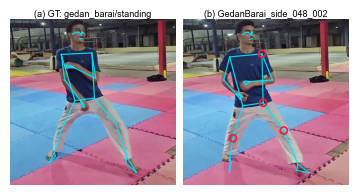

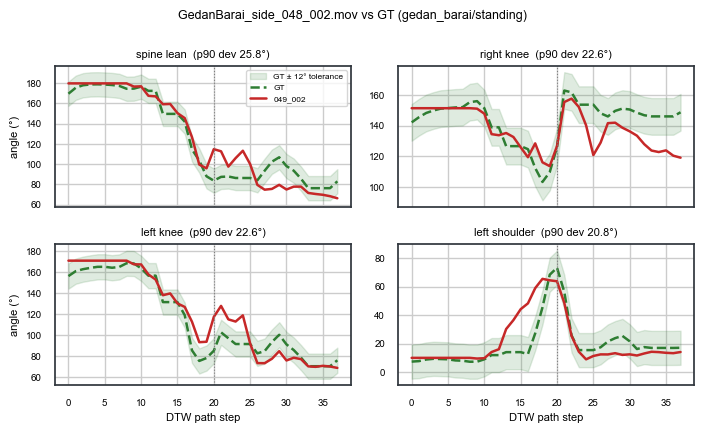


[RAG+LLM text stored by §7.1 (that cell truncates it to 300 chars)]
DTW (user vs GT):
   • spine_lean: 25.8° off — user 112.7° vs GT 87.4° (too extended/large)
   • right_knee: 22.6° off — user 123.7° vs GT 146.1° (too bent/small)
   • left_knee: 22.6° off — user 113.1° vs GT 91.7° (too extended/large)
   • left_shoulder: 20.8° off — user 65.6° vs GT 45.5° (too extended/large)

Text typeset under Fig A (141 chars):
First, bring your spine a touch more relaxed—think of letting the back of your neck ease
into a gentle curve rather than leaning straight up.

💾 Results\master_validation\gt_vs_049_002_frames.png | Results\master_validation\gt_vs_049_002_curves.png | Results\master_validation\gt_vs_049_002_feedback.tex | Results\master_validation\gt_vs_049_002_joints.csv


In [26]:
# ── §7.3 GT (Master reference) vs 049_002 — frames, angle curves, system text ─────────────────────────
# RUN AFTER §6.1, §7.1 and §7.2 (it re-uses feedback_errors, dtw_align, mirror9, _dtw_path, _draw, VERTEX,
# _mentions, _latex_escape, ablation_df, master_gt, trainee_records).
#
# Produces
#   (1) Fig A  gt_vs_049_002_frames.png   — paper figure: GT frame | 049_002 frame, SAME phase, flagged joints circled
#   (2) Fig B  gt_vs_049_002_curves.png   — analysis figure: user vs GT angle curves for the flagged joints (DTW-aligned)
#   (3) table of all 9 joints (p90 deviation, user value, GT value)  → gt_vs_049_002_joints.csv
#   (4) gt_vs_049_002_feedback.tex        — the system text (joint-relevant sentences only) to typeset UNDER the figure
#
# The GT only stores 9 angles x 30 frames, so the GT *picture* needs the exemplar video: it is looked up in
# MASTER_GT_DIR (<Move>_<stance>.mp4). If it is not found, Fig A shows only the 049_002 frame and Fig B still works.
import textwrap

CMP_PRAC, CMP_SUFFIX, CMP_MOVE = '048', '002', 'GedanBarai'
N_SHOWN            = 4        # joints circled in Fig A / plotted in Fig B
EXCERPT_CHARS      = 260      # budget for the text typeset under the figure
REGENERATE_LLM     = False    # False = use the text stored by §7.1 (cut at 300 chars there, see note below)
                              # True  = call RAG+LLM again for this clip to get a FULL, new text (non-deterministic!)
FIG_W_IN, FIG_H_IN = 3.45, 1.85

# ── pick the clip ─────────────────────────────────────────────────────────────────────────────────────
_c = [r for r in trainee_records if r['practitioner'] == CMP_PRAC and r['gt_label'] == CMP_MOVE
      and Path(r['video']).stem.endswith(CMP_SUFFIX)]
if not _c: raise RuntimeError(f"No {CMP_MOVE} clip of practitioner {CMP_PRAC} with suffix {CMP_SUFFIX}")
rec = _c[0]

# ── DTW against the GT (same logic as feedback_errors, but keeping the alignment) ───────────────────────
errs, user, ref, diff = feedback_errors(rec)               # diff is indexed by DTW-path row, not by frame
mir      = mirror9(user)
mirrored = _dtw_path(mir, ref) < _dtw_path(user, ref)
best     = mir if mirrored else user
path     = dtw_align(best, ref)                            # [(user_idx, ref_idx), ...]
ua       = best[[p[0] for p in path]]                      # user angles along the path (GT orientation)
ra       = ref[[p[1] for p in path]]                       # GT angles along the path
p90      = np.percentile(diff, 90, axis=0)
if not errs: raise RuntimeError("No flagged joint for this clip — nothing to compare.")
shown = [e['joint'] for e in errs[:N_SHOWN]]
print(f"{rec['video']}  |  GT key: {CMP_MOVE}/{rec['stance']}  |  mirrored user: {mirrored}  |  flagged {len(errs)}/9")

# ── (3) all 9 joints ──────────────────────────────────────────────────────────────────────────────────
rows = []
for k, name in enumerate(MASTER_ANGLE_NAMES):
    r_k = int(np.argmax(diff[:, k]))
    rows.append({'joint': name, 'p90 dev (deg)': round(float(p90[k]), 1), 'flagged': bool(p90[k] >= ERROR_THRESHOLD),
                 'mean dev (deg)': round(float(diff[:, k].mean()), 1),
                 'user @peak': round(float(ua[r_k, k]), 1), 'GT @peak': round(float(ra[r_k, k]), 1)})
joint_df = pd.DataFrame(rows).sort_values('p90 dev (deg)', ascending=False)
display(joint_df); joint_df.to_csv(RESULTS_DIR / 'gt_vs_049_002_joints.csv', index=False)

# ── phase to show: GT frame where the top flagged joint deviates most ─────────────────────────────────────
top_k  = MASTER_ANGLE_NAMES.index(errs[0]['joint'])
r_peak = int(np.argmax(diff[:, top_k])); ref_i, usr_i = path[r_peak][1], path[r_peak][0]
print(f"Phase shown: GT frame {ref_i}/{SEQ_LEN-1}, user frame {usr_i}/{SEQ_LEN-1} (peak of '{errs[0]['joint']}')")

# ── frame grabber for any video path (same detected-frame logic as video_landmark_frames) ────────────────
def _frame_from_path(vpath, idx):
    cap = cv2.VideoCapture(str(vpath))
    pose = mp.solutions.pose.Pose(static_image_mode=False, model_complexity=1,
                                  min_detection_confidence=0.5, min_tracking_confidence=0.5)
    det = []
    while True:
        ok, fr = cap.read()
        if not ok: break
        rgb = cv2.cvtColor(fr, cv2.COLOR_BGR2RGB); res = pose.process(rgb)
        if res.pose_landmarks:
            det.append((rgb, np.array([[l.x, l.y, l.z, l.visibility] for l in res.pose_landmarks.landmark], np.float32)))
    cap.release(); pose.close()
    if len(det) < SEQ_LEN: raise RuntimeError(f"{Path(vpath).name}: only {len(det)} detected frames")
    return det[np.linspace(0, len(det) - 1, SEQ_LEN).astype(int)[idx]]

img_u, lm_u = _frame_from_path(Path(TRAINEE_VID_DIR) / rec['video'], usr_i)

# ── find the GT exemplar video (<Move>_<stance>) ─────────────────────────────────────────────────────────
_want = (MOVE_MAP.get(CMP_MOVE.lower()), rec['stance'])
gt_videos = [vf for vf in sorted(Path(MASTER_GT_DIR).glob('*'))
             if vf.suffix.lower() in ('.mp4', '.mov', '.avi', '.mkv') and parse_master_name(vf.stem) == _want]
img_g = lm_g = None
if gt_videos:
    if len(gt_videos) > 1:
        print(f"⚠️ {len(gt_videos)} exemplar videos for {_want}: the GT is their AVERAGE, the picture uses {gt_videos[0].name} "
              f"(phase index is approximate).")
    img_g, lm_g = _frame_from_path(gt_videos[0], ref_i)
else:
    print(f"⚠️ no exemplar video for {_want} in MASTER_GT_DIR → Fig A shows only the 049_002 frame.")

# ── (1) Fig A — paper figure (text goes OUTSIDE the image, typeset by LaTeX) ──────────────────────────────
with plt.rc_context({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'text.color': 'black',
                     'axes.labelcolor': 'black', 'savefig.facecolor': 'white'}):
    n = 2 if img_g is not None else 1
    fig, axes = plt.subplots(1, n, figsize=(FIG_W_IN if n == 2 else FIG_W_IN / 2, FIG_H_IN))
    axes = np.atleast_1d(axes)
    if img_g is not None:
        _draw(axes[0], img_g, lm_g, f"(a) GT: {_want[0]}/{_want[1]}")
    _draw(axes[-1], img_u, lm_u, f"({'b' if n == 2 else 'a'}) {Path(rec['video']).stem}", flagged=shown, mirrored=mirrored)
    fig.subplots_adjust(left=0.005, right=0.995, top=0.90, bottom=0.005, wspace=0.03)
    fig.savefig(RESULTS_DIR / 'gt_vs_049_002_frames.png', dpi=300); plt.show()

# ── (2) Fig B — user vs GT angle curves for the flagged joints (analysis; DTW-aligned) ───────────────────
with plt.rc_context({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'text.color': 'black',
                     'axes.labelcolor': 'black', 'xtick.color': 'black', 'ytick.color': 'black', 'savefig.facecolor': 'white'}):
    fig, axs = plt.subplots(2, 2, figsize=(7.2, 4.4), sharex=True)
    for ax, jn in zip(axs.ravel(), shown):
        k = MASTER_ANGLE_NAMES.index(jn); x = np.arange(len(path))
        ax.fill_between(x, ra[:, k] - ERROR_THRESHOLD, ra[:, k] + ERROR_THRESHOLD, color='#2e7d32', alpha=.15,
                        label=f'GT ± {ERROR_THRESHOLD:.0f}° tolerance')
        ax.plot(x, ra[:, k], color='#2e7d32', lw=1.8, ls='--', label='GT')
        ax.plot(x, ua[:, k], color='#c62828', lw=1.8, label='049_002')
        ax.axvline(r_peak, color='gray', lw=.8, ls=':')
        ax.set_title(f"{jn.replace('_', ' ')}  (p90 dev {p90[k]:.1f}°)", fontsize=8); ax.tick_params(labelsize=7)
    for ax in axs[-1]: ax.set_xlabel('DTW path step', fontsize=8)
    for ax in axs[:, 0]: ax.set_ylabel('angle (°)', fontsize=8)
    axs[0, 0].legend(fontsize=6, loc='best')
    fig.suptitle(f"{rec['video']} vs GT ({_want[0]}/{_want[1]})" + ('  [user mirrored]' if mirrored else ''), fontsize=9)
    fig.tight_layout(); fig.savefig(RESULTS_DIR / 'gt_vs_049_002_curves.png', dpi=200); plt.show()

# ── (4) system text for under the figure: only sentences about the flagged joints ──────────────────────
if REGENERATE_LLM:
    full_text, live, _n = arm_rag_llm(rec['gt_label'], errs)
    src = f"RAG+LLM regenerated now (live={live}) — differs from the §7.1 row"
else:
    full_text = ablation_df.loc[ablation_df['video'] == rec['video'], 'RAG+LLM (ours)'].iloc[0]
    src = "RAG+LLM text stored by §7.1 (that cell truncates it to 300 chars)"

def _pick_sentences(text, joints, budget):
    t = re.sub(r'\s+', ' ', re.sub(r'\*\*?|__|[#>]+', '', str(text))).strip()
    sents = re.split(r'(?<=[.!?])\s+', t)
    keep = [s for s in sents if any(_mentions(s, j) for j in joints)]       # drop greetings / pep-talk
    keep = keep or sents
    out, used = [], 0
    for s in keep:
        if used + len(s) > budget and out: break
        out.append(s); used += len(s) + 1
    return ' '.join(out)

excerpt = _pick_sentences(full_text, shown, EXCERPT_CHARS)
tex = "\\par\\smallskip\\textit{System text:} ``" + _latex_escape(excerpt) + "''\n"
(RESULTS_DIR / 'gt_vs_049_002_feedback.tex').write_text(tex, encoding='utf-8')

print(f"\n[{src}]")
print("DTW (user vs GT):")
for e in errs[:N_SHOWN]:
    print(f"   • {e['joint']}: {e['mean_error']}° off — user {e['user_val']}° vs GT {e['ref_val']}° ({e['direction']})")
print(f"\nText typeset under Fig A ({len(excerpt)} chars):\n" + textwrap.fill(excerpt, 90))
print(f"\n💾 {RESULTS_DIR/'gt_vs_049_002_frames.png'} | {RESULTS_DIR/'gt_vs_049_002_curves.png'} | "
      f"{RESULTS_DIR/'gt_vs_049_002_feedback.tex'} | {RESULTS_DIR/'gt_vs_049_002_joints.csv'}")

MaeGeri_zenkutsu_side_051_002.mov  |  GT key: MaeGeri/zenkutsu  |  mirrored user: False  |  flagged 9/9


,joint,p90 dev (deg),flagged,mean dev (deg),user @peak,GT @peak
4,right_knee,91.0,True,33.3,147.5,38.2
1,left_elbow,53.7,True,24.0,95.9,159.1
0,right_elbow,41.1,True,27.3,162.3,86.2
3,left_shoulder,41.1,True,14.9,5.9,65.1
2,right_shoulder,31.1,True,12.4,32.6,72.8
5,left_knee,29.6,True,13.5,106.1,69.7
7,left_hip,29.2,True,12.5,158.0,126.7
6,right_hip,27.7,True,15.2,171.3,77.2
8,spine_lean,16.8,True,9.5,169.6,133.5


Phase shown: GT frame 15/29, user frame 17/29 (peak of 'right_knee')


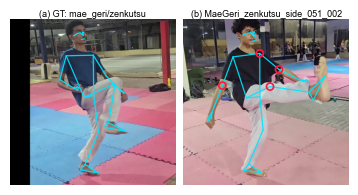

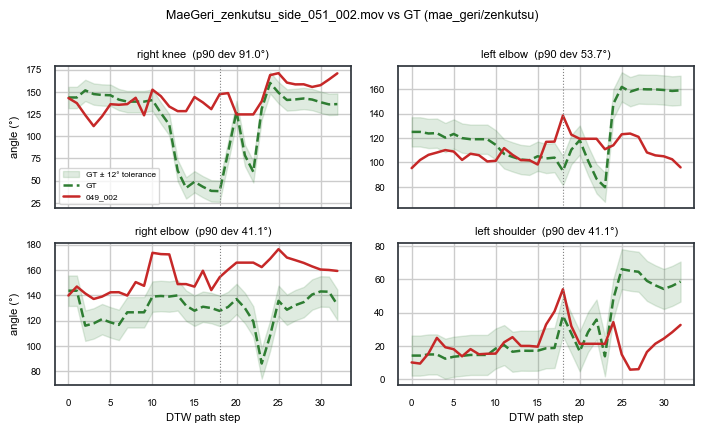


[RAG+LLM text stored by §7.1 (that cell truncates it to 300 chars)]
DTW (user vs GT):
   • right_knee: 91.0° off — user 130.6° vs GT 38.5° (too extended/large)
   • left_elbow: 53.7° off — user 105.8° vs GT 159.9° (too bent/small)
   • right_elbow: 41.1° off — user 169.8° vs GT 128.6° (too extended/large)
   • left_shoulder: 41.1° off — user 16.5° vs GT 59.1° (too bent/small)

Text typeset under Fig A (101 chars):
First, keep the kicking knee straight and locked—think of a straight line from your hip to
your toes.

💾 Results\master_validation\gt_vs_049_002_frames.png | Results\master_validation\gt_vs_049_002_curves.png | Results\master_validation\gt_vs_049_002_feedback.tex | Results\master_validation\gt_vs_049_002_joints.csv


In [27]:
# ── §7.3 GT (Master reference) vs 049_002 — frames, angle curves, system text ─────────────────────────
# RUN AFTER §6.1, §7.1 and §7.2 (it re-uses feedback_errors, dtw_align, mirror9, _dtw_path, _draw, VERTEX,
# _mentions, _latex_escape, ablation_df, master_gt, trainee_records).
#
# Produces
#   (1) Fig A  gt_vs_049_002_frames.png   — paper figure: GT frame | 049_002 frame, SAME phase, flagged joints circled
#   (2) Fig B  gt_vs_049_002_curves.png   — analysis figure: user vs GT angle curves for the flagged joints (DTW-aligned)
#   (3) table of all 9 joints (p90 deviation, user value, GT value)  → gt_vs_049_002_joints.csv
#   (4) gt_vs_049_002_feedback.tex        — the system text (joint-relevant sentences only) to typeset UNDER the figure
#
# The GT only stores 9 angles x 30 frames, so the GT *picture* needs the exemplar video: it is looked up in
# MASTER_GT_DIR (<Move>_<stance>.mp4). If it is not found, Fig A shows only the 049_002 frame and Fig B still works.
import textwrap

CMP_PRAC, CMP_SUFFIX, CMP_MOVE = '051', '002', 'MaeGeri'
N_SHOWN            = 4        # joints circled in Fig A / plotted in Fig B
EXCERPT_CHARS      = 260      # budget for the text typeset under the figure
REGENERATE_LLM     = False    # False = use the text stored by §7.1 (cut at 300 chars there, see note below)
                              # True  = call RAG+LLM again for this clip to get a FULL, new text (non-deterministic!)
FIG_W_IN, FIG_H_IN = 3.45, 1.85

# ── pick the clip ─────────────────────────────────────────────────────────────────────────────────────
_c = [r for r in trainee_records if r['practitioner'] == CMP_PRAC and r['gt_label'] == CMP_MOVE
      and Path(r['video']).stem.endswith(CMP_SUFFIX)]
if not _c: raise RuntimeError(f"No {CMP_MOVE} clip of practitioner {CMP_PRAC} with suffix {CMP_SUFFIX}")
rec = _c[0]

# ── DTW against the GT (same logic as feedback_errors, but keeping the alignment) ───────────────────────
errs, user, ref, diff = feedback_errors(rec)               # diff is indexed by DTW-path row, not by frame
mir      = mirror9(user)
mirrored = _dtw_path(mir, ref) < _dtw_path(user, ref)
best     = mir if mirrored else user
path     = dtw_align(best, ref)                            # [(user_idx, ref_idx), ...]
ua       = best[[p[0] for p in path]]                      # user angles along the path (GT orientation)
ra       = ref[[p[1] for p in path]]                       # GT angles along the path
p90      = np.percentile(diff, 90, axis=0)
if not errs: raise RuntimeError("No flagged joint for this clip — nothing to compare.")
shown = [e['joint'] for e in errs[:N_SHOWN]]
print(f"{rec['video']}  |  GT key: {CMP_MOVE}/{rec['stance']}  |  mirrored user: {mirrored}  |  flagged {len(errs)}/9")

# ── (3) all 9 joints ──────────────────────────────────────────────────────────────────────────────────
rows = []
for k, name in enumerate(MASTER_ANGLE_NAMES):
    r_k = int(np.argmax(diff[:, k]))
    rows.append({'joint': name, 'p90 dev (deg)': round(float(p90[k]), 1), 'flagged': bool(p90[k] >= ERROR_THRESHOLD),
                 'mean dev (deg)': round(float(diff[:, k].mean()), 1),
                 'user @peak': round(float(ua[r_k, k]), 1), 'GT @peak': round(float(ra[r_k, k]), 1)})
joint_df = pd.DataFrame(rows).sort_values('p90 dev (deg)', ascending=False)
display(joint_df); joint_df.to_csv(RESULTS_DIR / 'gt_vs_049_002_joints.csv', index=False)

# ── phase to show: GT frame where the top flagged joint deviates most ─────────────────────────────────────
top_k  = MASTER_ANGLE_NAMES.index(errs[0]['joint'])
r_peak = int(np.argmax(diff[:, top_k])); ref_i, usr_i = path[r_peak][1], path[r_peak][0]
print(f"Phase shown: GT frame {ref_i}/{SEQ_LEN-1}, user frame {usr_i}/{SEQ_LEN-1} (peak of '{errs[0]['joint']}')")

# ── frame grabber for any video path (same detected-frame logic as video_landmark_frames) ────────────────
def _frame_from_path(vpath, idx):
    cap = cv2.VideoCapture(str(vpath))
    pose = mp.solutions.pose.Pose(static_image_mode=False, model_complexity=1,
                                  min_detection_confidence=0.5, min_tracking_confidence=0.5)
    det = []
    while True:
        ok, fr = cap.read()
        if not ok: break
        rgb = cv2.cvtColor(fr, cv2.COLOR_BGR2RGB); res = pose.process(rgb)
        if res.pose_landmarks:
            det.append((rgb, np.array([[l.x, l.y, l.z, l.visibility] for l in res.pose_landmarks.landmark], np.float32)))
    cap.release(); pose.close()
    if len(det) < SEQ_LEN: raise RuntimeError(f"{Path(vpath).name}: only {len(det)} detected frames")
    return det[np.linspace(0, len(det) - 1, SEQ_LEN).astype(int)[idx]]

img_u, lm_u = _frame_from_path(Path(TRAINEE_VID_DIR) / rec['video'], usr_i)

# ── find the GT exemplar video (<Move>_<stance>) ─────────────────────────────────────────────────────────
_want = (MOVE_MAP.get(CMP_MOVE.lower()), rec['stance'])
gt_videos = [vf for vf in sorted(Path(MASTER_GT_DIR).glob('*'))
             if vf.suffix.lower() in ('.mp4', '.mov', '.avi', '.mkv') and parse_master_name(vf.stem) == _want]
img_g = lm_g = None
if gt_videos:
    if len(gt_videos) > 1:
        print(f"⚠️ {len(gt_videos)} exemplar videos for {_want}: the GT is their AVERAGE, the picture uses {gt_videos[0].name} "
              f"(phase index is approximate).")
    img_g, lm_g = _frame_from_path(gt_videos[0], ref_i)
else:
    print(f"⚠️ no exemplar video for {_want} in MASTER_GT_DIR → Fig A shows only the 049_002 frame.")

# ── (1) Fig A — paper figure (text goes OUTSIDE the image, typeset by LaTeX) ──────────────────────────────
with plt.rc_context({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'text.color': 'black',
                     'axes.labelcolor': 'black', 'savefig.facecolor': 'white'}):
    n = 2 if img_g is not None else 1
    fig, axes = plt.subplots(1, n, figsize=(FIG_W_IN if n == 2 else FIG_W_IN / 2, FIG_H_IN))
    axes = np.atleast_1d(axes)
    if img_g is not None:
        _draw(axes[0], img_g, lm_g, f"(a) GT: {_want[0]}/{_want[1]}")
    _draw(axes[-1], img_u, lm_u, f"({'b' if n == 2 else 'a'}) {Path(rec['video']).stem}", flagged=shown, mirrored=mirrored)
    fig.subplots_adjust(left=0.005, right=0.995, top=0.90, bottom=0.005, wspace=0.03)
    fig.savefig(RESULTS_DIR / 'gt_vs_049_002_frames.png', dpi=300); plt.show()

# ── (2) Fig B — user vs GT angle curves for the flagged joints (analysis; DTW-aligned) ───────────────────
with plt.rc_context({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'text.color': 'black',
                     'axes.labelcolor': 'black', 'xtick.color': 'black', 'ytick.color': 'black', 'savefig.facecolor': 'white'}):
    fig, axs = plt.subplots(2, 2, figsize=(7.2, 4.4), sharex=True)
    for ax, jn in zip(axs.ravel(), shown):
        k = MASTER_ANGLE_NAMES.index(jn); x = np.arange(len(path))
        ax.fill_between(x, ra[:, k] - ERROR_THRESHOLD, ra[:, k] + ERROR_THRESHOLD, color='#2e7d32', alpha=.15,
                        label=f'GT ± {ERROR_THRESHOLD:.0f}° tolerance')
        ax.plot(x, ra[:, k], color='#2e7d32', lw=1.8, ls='--', label='GT')
        ax.plot(x, ua[:, k], color='#c62828', lw=1.8, label='049_002')
        ax.axvline(r_peak, color='gray', lw=.8, ls=':')
        ax.set_title(f"{jn.replace('_', ' ')}  (p90 dev {p90[k]:.1f}°)", fontsize=8); ax.tick_params(labelsize=7)
    for ax in axs[-1]: ax.set_xlabel('DTW path step', fontsize=8)
    for ax in axs[:, 0]: ax.set_ylabel('angle (°)', fontsize=8)
    axs[0, 0].legend(fontsize=6, loc='best')
    fig.suptitle(f"{rec['video']} vs GT ({_want[0]}/{_want[1]})" + ('  [user mirrored]' if mirrored else ''), fontsize=9)
    fig.tight_layout(); fig.savefig(RESULTS_DIR / 'gt_vs_049_002_curves.png', dpi=200); plt.show()

# ── (4) system text for under the figure: only sentences about the flagged joints ──────────────────────
if REGENERATE_LLM:
    full_text, live, _n = arm_rag_llm(rec['gt_label'], errs)
    src = f"RAG+LLM regenerated now (live={live}) — differs from the §7.1 row"
else:
    full_text = ablation_df.loc[ablation_df['video'] == rec['video'], 'RAG+LLM (ours)'].iloc[0]
    src = "RAG+LLM text stored by §7.1 (that cell truncates it to 300 chars)"

def _pick_sentences(text, joints, budget):
    t = re.sub(r'\s+', ' ', re.sub(r'\*\*?|__|[#>]+', '', str(text))).strip()
    sents = re.split(r'(?<=[.!?])\s+', t)
    keep = [s for s in sents if any(_mentions(s, j) for j in joints)]       # drop greetings / pep-talk
    keep = keep or sents
    out, used = [], 0
    for s in keep:
        if used + len(s) > budget and out: break
        out.append(s); used += len(s) + 1
    return ' '.join(out)

excerpt = _pick_sentences(full_text, shown, EXCERPT_CHARS)
tex = "\\par\\smallskip\\textit{System text:} ``" + _latex_escape(excerpt) + "''\n"
(RESULTS_DIR / 'gt_vs_049_002_feedback.tex').write_text(tex, encoding='utf-8')

print(f"\n[{src}]")
print("DTW (user vs GT):")
for e in errs[:N_SHOWN]:
    print(f"   • {e['joint']}: {e['mean_error']}° off — user {e['user_val']}° vs GT {e['ref_val']}° ({e['direction']})")
print(f"\nText typeset under Fig A ({len(excerpt)} chars):\n" + textwrap.fill(excerpt, 90))
print(f"\n💾 {RESULTS_DIR/'gt_vs_049_002_frames.png'} | {RESULTS_DIR/'gt_vs_049_002_curves.png'} | "
      f"{RESULTS_DIR/'gt_vs_049_002_feedback.tex'} | {RESULTS_DIR/'gt_vs_049_002_joints.csv'}")


GedanBarai_side_049_002.mov | GT key gedan_barai_from_standing | mirrored user: False | flagged 9/9


,joint,p90 dev (deg),flagged,mean dev (deg),user @peak,GT @peak
0,right_elbow,65.2,True,34.4,154.8,71.7
5,left_knee,45.9,True,18.5,119.2,168.6
3,left_shoulder,41.5,True,20.6,67.6,15.5
4,right_knee,40.6,True,15.4,110.9,156.0
2,right_shoulder,38.8,True,11.2,59.3,12.2
1,left_elbow,34.6,True,21.2,91.6,130.7
8,spine_lean,34.6,True,17.5,70.2,106.8
6,right_hip,33.8,True,13.3,125.4,163.9
7,left_hip,14.5,True,6.1,87.3,110.7


Phase shown: GT frame 29/29, trainee frame 29/29 (peak of 'right_elbow')


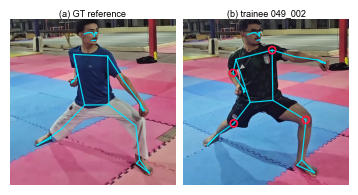

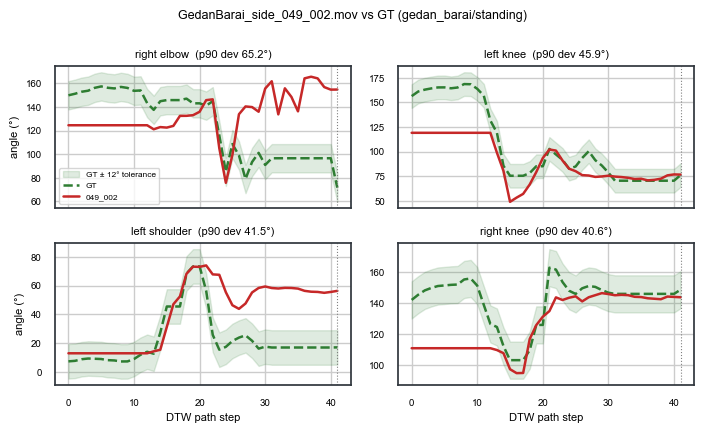

⚠️ stored text is exactly 300 chars → §7.1 still truncates it; apply the patch in the header and re-run §7.1.
[RAG+LLM text stored by §7.1]
DTW (trainee vs GT):
   • right_elbow: 65.2° off — trainee 161.8° vs GT 96.6° (too extended/large)
   • left_knee: 45.9° off — trainee 119.2° vs GT 165.1° (too bent/small)
   • left_shoulder: 41.5° off — trainee 58.5° vs GT 17.0° (too extended/large)
   • right_knee: 40.6° off — trainee 110.9° vs GT 151.5° (too bent/small)

FULL system text:
Hey there! I noticed a few spots that could use a little tweak to make your Gedan‑Barai feel more
natural and powerful.  **Elbows & Shoulders**   Your right elbow is a bit too straight, so try
letting it bend a little—imagine a gentle curve in your arm, keeping the forearm almost parallel to
the flo

Excerpt typeset under the figure (173 chars):
Elbows & Shoulders Your right elbow is a bit too straight, so try letting it bend a little—imagine a
gentle curve in your arm, keeping the forearm almost parallel to th

,joint,p90 dev (deg),flagged,mean dev (deg),user @peak,GT @peak
4,right_knee,91.0,True,33.3,147.5,38.2
1,left_elbow,53.7,True,24.0,95.9,159.1
0,right_elbow,41.1,True,27.3,162.3,86.2
3,left_shoulder,41.1,True,14.9,5.9,65.1
2,right_shoulder,31.1,True,12.4,32.6,72.8
5,left_knee,29.6,True,13.5,106.1,69.7
7,left_hip,29.2,True,12.5,158.0,126.7
6,right_hip,27.7,True,15.2,171.3,77.2
8,spine_lean,16.8,True,9.5,169.6,133.5


Phase shown: GT frame 15/29, trainee frame 17/29 (peak of 'right_knee')


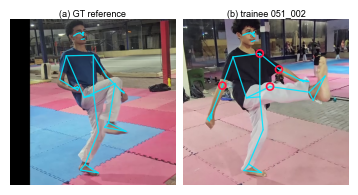

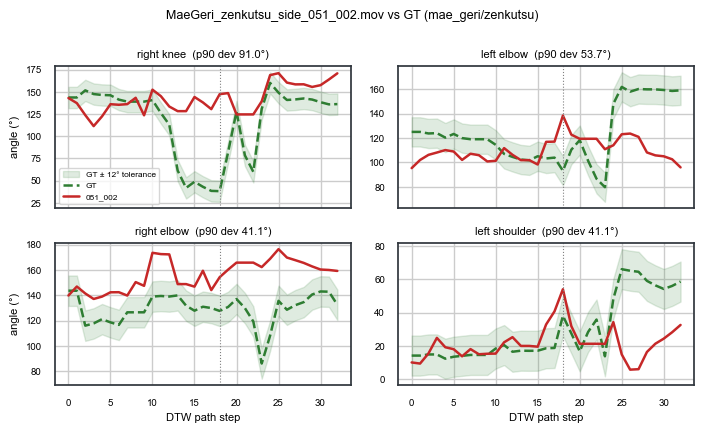

⚠️ stored text is exactly 300 chars → §7.1 still truncates it; apply the patch in the header and re-run §7.1.
[RAG+LLM text stored by §7.1]
DTW (trainee vs GT):
   • right_knee: 91.0° off — trainee 130.6° vs GT 38.5° (too extended/large)
   • left_elbow: 53.7° off — trainee 105.8° vs GT 159.9° (too bent/small)
   • right_elbow: 41.1° off — trainee 169.8° vs GT 128.6° (too extended/large)
   • left_shoulder: 41.1° off — trainee 16.5° vs GT 59.1° (too bent/small)

FULL system text:
Great effort on that MaeGeri! I noticed a few spots that can use a bit of tightening to bring the
form together.  First, keep the kicking knee straight and locked—think of a straight line from your
hip to your toes. Let the supporting leg stay slightly bent for balance and power. For your arms,
rela

Excerpt typeset under the figure (101 chars):
First, keep the kicking knee straight and locked—think of a straight line from your hip to your
toes.

👀 CHECK BY EYE: does the text push the SAME direction as the DTW

In [29]:
# ── §7.3 GT reference vs trainee clips (Gedan Barai + Mae Geri) — unique filenames per clip ───────────────
# RUN AFTER §6.1, §7.1 and §7.2 (re-uses feedback_errors, dtw_align, mirror9, _dtw_path, _draw, _mentions,
# _latex_escape, auto_checks, arm_rag_llm, ablation_df, trainee_records, MASTER_GT_DIR ...).
#
# !! BEFORE running this cell, fix §7.1 once (otherwise every stored text is cut at 300 characters):
#       in §7.1 replace
#           'Direct LLM': t_dir[:300], 'RAG+LLM (ours)': t_rag[:300],
#       with
#           'Direct LLM': t_dir, 'RAG+LLM (ours)': t_rag,
#    and re-run §7.1 ONCE. Then feedback_ablation_full.json really is full, and the text shown under the figures
#    is a quote of the SAME call that the ablation table was computed from (no cherry-picking a new generation).
#
# Per clip it writes (tag = gt_vs_<Move>_<prac>_<suffix>):
#   <tag>_frames.png   paper figure: GT frame | trainee frame at the same phase, flagged joints circled (no text inside)
#   <tag>_curves.png   analysis figure: trainee vs GT angle curves of the flagged joints (DTW-aligned)
#   <tag>_joints.csv   all 9 joints: p90 deviation, flagged?, values at the peak
#   <tag>_caption.tex  DTW line + system text, to typeset UNDER the figure (not inside it)
#   gt_vs_cases_feedback.json   full system text, the shortened excerpt and the automatic checks for every case
import textwrap

CASES         = [('049', '002', 'GedanBarai'), ('051', '002', 'MaeGeri')]   # (practitioner, clip suffix, technique)
N_SHOWN       = 4          # joints circled in the frame figure / plotted in the curve figure
EXCERPT_CHARS = 260        # budget for the text typeset under the figure
REGENERATE_LLM = False     # False = text stored by §7.1 (recommended); True = a NEW live generation (non-deterministic)
FIG_W_IN, FIG_H_IN = 3.45, 1.85

def _frame_from_path(vpath, idx):
    """Same detected-frame logic as video_landmark_frames; returns (rgb image, landmarks[33,4]) of the idx-th of 30 frames."""
    cap = cv2.VideoCapture(str(vpath))
    pose = mp.solutions.pose.Pose(static_image_mode=False, model_complexity=1,
                                  min_detection_confidence=0.5, min_tracking_confidence=0.5)
    det = []
    while True:
        ok, fr = cap.read()
        if not ok: break
        rgb = cv2.cvtColor(fr, cv2.COLOR_BGR2RGB); res = pose.process(rgb)
        if res.pose_landmarks:
            det.append((rgb, np.array([[l.x, l.y, l.z, l.visibility] for l in res.pose_landmarks.landmark], np.float32)))
    cap.release(); pose.close()
    if len(det) < SEQ_LEN: raise RuntimeError(f"{Path(vpath).name}: only {len(det)} detected frames")
    return det[np.linspace(0, len(det) - 1, SEQ_LEN).astype(int)[idx]]

def _pick_sentences(text, joints, budget):
    """Keep only sentences that talk about the flagged joints (drops greetings / pep-talk), within a character budget."""
    t = re.sub(r'\s+', ' ', re.sub(r'\*\*?|__|[#>]+', '', str(text))).strip()
    sents = re.split(r'(?<=[.!?])\s+', t)
    keep = [s for s in sents if any(_mentions(s, j) for j in joints)] or sents
    out, used = [], 0
    for s in keep:
        if used + len(s) > budget and out: break
        out.append(s); used += len(s) + 1
    return ' '.join(out)

_WHITE = {'figure.facecolor': 'white', 'axes.facecolor': 'white', 'text.color': 'black', 'axes.labelcolor': 'black',
          'xtick.color': 'black', 'ytick.color': 'black', 'savefig.facecolor': 'white'}

def gt_vs_clip(prac, suffix, move):
    tag = f"gt_vs_{move}_{prac}_{suffix}"
    c = [r for r in trainee_records if r['practitioner'] == prac and r['gt_label'] == move
         and Path(r['video']).stem.endswith(suffix)]
    if not c: raise RuntimeError(f"No {move} clip of practitioner {prac} with suffix {suffix}")
    rec = c[0]

    # DTW against the GT (same logic as feedback_errors, keeping the alignment)
    errs, user, ref, diff = feedback_errors(rec)               # diff is indexed by DTW-path row, not by frame
    mir = mirror9(user); mirrored = _dtw_path(mir, ref) < _dtw_path(user, ref)
    best = mir if mirrored else user
    path = dtw_align(best, ref)                                # [(user_idx, ref_idx), ...]
    ua = best[[p[0] for p in path]]; ra = ref[[p[1] for p in path]]
    p90 = np.percentile(diff, 90, axis=0)
    if not errs: raise RuntimeError(f"{rec['video']}: no flagged joint — nothing to compare.")
    shown = [e['joint'] for e in errs[:N_SHOWN]]
    want = (MOVE_MAP.get(move.lower()), rec['stance'])
    print(f"\n{'='*100}\n{rec['video']} | GT key {want[0]}_from_{want[1]} | mirrored user: {mirrored} | flagged {len(errs)}/9")

    # all 9 joints
    rows = []
    for k, name in enumerate(MASTER_ANGLE_NAMES):
        r_k = int(np.argmax(diff[:, k]))
        rows.append({'joint': name, 'p90 dev (deg)': round(float(p90[k]), 1), 'flagged': bool(p90[k] >= ERROR_THRESHOLD),
                     'mean dev (deg)': round(float(diff[:, k].mean()), 1),
                     'user @peak': round(float(ua[r_k, k]), 1), 'GT @peak': round(float(ra[r_k, k]), 1)})
    joint_df = pd.DataFrame(rows).sort_values('p90 dev (deg)', ascending=False)
    display(joint_df); joint_df.to_csv(RESULTS_DIR / f'{tag}_joints.csv', index=False)

    # phase to show: GT frame where the top flagged joint deviates most
    top_k = MASTER_ANGLE_NAMES.index(errs[0]['joint'])
    r_peak = int(np.argmax(diff[:, top_k])); ref_i, usr_i = path[r_peak][1], path[r_peak][0]
    print(f"Phase shown: GT frame {ref_i}/{SEQ_LEN-1}, trainee frame {usr_i}/{SEQ_LEN-1} (peak of '{errs[0]['joint']}')")
    img_u, lm_u = _frame_from_path(Path(TRAINEE_VID_DIR) / rec['video'], usr_i)

    gt_videos = [vf for vf in sorted(Path(MASTER_GT_DIR).glob('*'))
                 if vf.suffix.lower() in ('.mp4', '.mov', '.avi', '.mkv') and parse_master_name(vf.stem) == want]
    img_g = lm_g = None
    if gt_videos:
        if len(gt_videos) > 1:
            print(f"⚠️ {len(gt_videos)} exemplar videos for {want}: GT is their AVERAGE, picture uses {gt_videos[0].name} (phase approximate).")
        img_g, lm_g = _frame_from_path(gt_videos[0], ref_i)
    else:
        print(f"⚠️ no exemplar video for {want} in MASTER_GT_DIR → frame figure shows only the trainee frame.")

    # frame figure (NO text inside the image — the text is typeset by LaTeX)
    with plt.rc_context(_WHITE):
        n = 2 if img_g is not None else 1
        fig, axes = plt.subplots(1, n, figsize=(FIG_W_IN if n == 2 else FIG_W_IN / 2, FIG_H_IN)); axes = np.atleast_1d(axes)
        if img_g is not None: _draw(axes[0], img_g, lm_g, "(a) GT reference")
        _draw(axes[-1], img_u, lm_u, f"({'b' if n == 2 else 'a'}) trainee {prac}_{suffix}", flagged=shown, mirrored=mirrored)
        fig.subplots_adjust(left=0.005, right=0.995, top=0.90, bottom=0.005, wspace=0.03)
        fig.savefig(RESULTS_DIR / f'{tag}_frames.png', dpi=300); plt.show()

    # curve figure (analysis)
    with plt.rc_context(_WHITE):
        fig, axs = plt.subplots(2, 2, figsize=(7.2, 4.4), sharex=True)
        for ax, jn in zip(axs.ravel(), shown):
            k = MASTER_ANGLE_NAMES.index(jn); x = np.arange(len(path))
            ax.fill_between(x, ra[:, k] - ERROR_THRESHOLD, ra[:, k] + ERROR_THRESHOLD, color='#2e7d32', alpha=.15,
                            label=f'GT ± {ERROR_THRESHOLD:.0f}° tolerance')
            ax.plot(x, ra[:, k], color='#2e7d32', lw=1.8, ls='--', label='GT')
            ax.plot(x, ua[:, k], color='#c62828', lw=1.8, label=f'{prac}_{suffix}')
            ax.axvline(r_peak, color='gray', lw=.8, ls=':')
            ax.set_title(f"{jn.replace('_', ' ')}  (p90 dev {p90[k]:.1f}°)", fontsize=8); ax.tick_params(labelsize=7)
        for ax in axs[-1]: ax.set_xlabel('DTW path step', fontsize=8)
        for ax in axs[:, 0]: ax.set_ylabel('angle (°)', fontsize=8)
        axs[0, 0].legend(fontsize=6, loc='best')
        fig.suptitle(f"{rec['video']} vs GT ({want[0]}/{want[1]})" + ('  [trainee mirrored]' if mirrored else ''), fontsize=9)
        fig.tight_layout(); fig.savefig(RESULTS_DIR / f'{tag}_curves.png', dpi=200); plt.show()

    # system text + DTW line for UNDER the figure
    if REGENERATE_LLM:
        full_text, live, _n = arm_rag_llm(rec['gt_label'], errs); src = f"RAG+LLM regenerated now (live={live}); differs from §7.1"
    else:
        full_text = ablation_df.loc[ablation_df['video'] == rec['video'], 'RAG+LLM (ours)'].iloc[0]
        src = "RAG+LLM text stored by §7.1"
        if len(str(full_text)) == 300: print("⚠️ stored text is exactly 300 chars → §7.1 still truncates it; apply the patch in the header and re-run §7.1.")
    excerpt = _pick_sentences(full_text, shown, EXCERPT_CHARS)
    sign = lambda e: ('+' if e['direction'].startswith('too extended') else '-') + f"{e['mean_error']:.1f}"
    dtw_line = ', '.join(f"{e['joint'].replace('_', ' ')} ${sign(e)}^\\circ$" for e in errs[:N_SHOWN])
    (RESULTS_DIR / f'{tag}_caption.tex').write_text(
        "\\textbf{DTW (trainee vs.\\ GT):} " + dtw_line + ".\\par\\smallskip\\textit{System text:} ``" + _latex_escape(excerpt) + "''\n",
        encoding='utf-8')

    print(f"[{src}]\nDTW (trainee vs GT):")
    for e in errs[:N_SHOWN]:
        print(f"   • {e['joint']}: {e['mean_error']}° off — trainee {e['user_val']}° vs GT {e['ref_val']}° ({e['direction']})")
    print(f"\nFULL system text:\n" + textwrap.fill(str(full_text), 100))
    print(f"\nExcerpt typeset under the figure ({len(excerpt)} chars):\n" + textwrap.fill(excerpt, 100))
    print("\n👀 CHECK BY EYE: does the text push the SAME direction as the DTW line above (e.g. 'too extended' → advice to bend)?")
    return {'tag': tag, 'video': rec['video'], 'source': src, 'full_text': str(full_text), 'excerpt': excerpt,
            'checks': auto_checks(str(full_text), errs), 'dtw_top': errs[:N_SHOWN]}

results = [gt_vs_clip(*c) for c in CASES]
with open(RESULTS_DIR / 'gt_vs_cases_feedback.json', 'w', encoding='utf-8') as fh:
    json.dump(results, fh, ensure_ascii=False, indent=1, default=str)
print("\n💾 per clip: <tag>_frames.png, <tag>_curves.png, <tag>_joints.csv, <tag>_caption.tex  +  gt_vs_cases_feedback.json  →", RESULTS_DIR)

## §8 — Paper-Ready Summary Export
Everything above is written to `Results/master_validation/`:
`clip_audit.csv`, `cv_results.csv`, `cv_fold_membership.csv`, `trainee9_classification.csv`,
`ood_scores.csv`, `ood_roc.png`, `mean_vs_max_proof.png`, `confusion_golden.png`, `feedback_ablation.csv`, `fig_trainee.png` and `trainee_feedback.tex` (qualitative figure, §7.2).


In [19]:
# ── §8.1 One consolidated summary table ───────────────────────────────────────
summary = {
  'Dataset': f"{N_CLIPS} clips / {meta_df['practitioner_id'].nunique()} practitioners",
  'Train/Test split': f"{len(train_clips)} clips ({train_meta['practitioner_id'].nunique()} prac) / {len(test_clips)} clips ({test_meta['practitioner_id'].nunique()} prac)",
  'Excluded practitioners': f"{sorted(EXCLUDE_PRACTITIONERS)} (exemplar/trainee identities)",
  'Leakage': 'ZERO (GroupKFold + golden split; early stopping on train-carved validation)',
  'CV Dual-Stem': cv_table.loc['Dual-Stem Fusion','Mean ± Std'],
  'CV Single Bi-LSTM': cv_table.loc['Single Bi-LSTM','Mean ± Std'],
  'CV XGBoost': cv_table.loc['XGBoost','Mean ± Std'],
  'CV Random Forest': cv_table.loc['Random Forest','Mean ± Std'],
  'Paired t-test p (Dual vs Single)': f"{p_val:.4f}",
  'Golden split (all models)': '; '.join(f"{r['model']} {r['accuracy %']}%" for r in golden_df.to_dict('records')),
  f'Trainee set ({len(res_df)} clips) acc': f"Dual {acc_d:.1f}% | Single {acc_s:.1f}% | XGB {acc_x:.1f}% | RF {acc_r:.1f}%",
  'OOD thresholds': f"τ₁={CONF_THR}, τ₂={MARGIN_THR}, τ₃={DTW_THR}°",
  'GT source': 'NEW isolated Master videos (Savitzky-Golay w=5, stance-specific keys)',
}
for k, v in summary.items(): print(f"{k:32s}: {v}")
print("\n🎉 Notebook complete — attach Results/master_validation/ figures to the resubmission.")


Dataset                         : 484 clips / 51 practitioners
Train/Test split                : 387 clips (40 prac) / 97 clips (11 prac)
Excluded practitioners          : ['048', '049', '050', '051'] (exemplar/trainee identities)
Leakage                         : ZERO (GroupKFold + golden split; early stopping on train-carved validation)
CV Dual-Stem                    : 75.17 ± 16.59
CV Single Bi-LSTM               : 79.08 ± 14.67
CV XGBoost                      : 88.83 ± 6.06
CV Random Forest                : 91.31 ± 3.95
Paired t-test p (Dual vs Single): 0.6122
Golden split (all models)       : Dual-Stem Fusion 84.54%; Single Bi-LSTM 87.63%; XGBoost 88.66%; Random Forest 84.54%
Trainee set (11 clips) acc      : Dual 81.8% | Single 81.8% | XGB 72.7% | RF 72.7%
OOD thresholds                  : τ₁=0.65, τ₂=0.15, τ₃=35.0°
GT source                       : NEW isolated Master videos (Savitzky-Golay w=5, stance-specific keys)

🎉 Notebook complete — attach Results/master_validation/ figu

## Paper text to add — Related Work (depth-sensor datasets) *(verify every citation against the original before submitting)*

Most publicly available datasets for skeleton-based action recognition and motion assessment were captured with depth sensors (Microsoft Kinect or similar RGB-D devices) or marker/multi-camera studio rigs, which supply 3D joint positions directly. Examples are MSR Action3D [1], UTKinect-Action3D [2], Berkeley MHAD [3], NTU RGB+D [4], and MADS (martial arts, dance and sports) [5]. Models trained on these assume clean, sensor-provided 3D skeletons. Our setting differs: the data are monocular RGB phone videos in which MediaPipe estimates the pose, so the joint-angle features carry estimation noise, self-occlusion and viewpoint variation that depth-camera datasets do not exhibit. This motivates (i) an angle-based feature representation, (ii) a practitioner-disjoint evaluation protocol, and (iii) an explicit out-of-distribution rejection stage.

**References (verify details):**
1. W. Li, Z. Zhang, Z. Liu. *Action recognition based on a bag of 3D points.* CVPR Workshops, 2010. (MSR Action3D, depth)
2. L. Xia, C.-C. Chen, J. K. Aggarwal. *View invariant human action recognition using histograms of 3D joints.* CVPR Workshops, 2012. (UTKinect-Action3D, Kinect)
3. F. Ofli, R. Chaudhry, G. Kurillo, R. Vidal, R. Bajcsy. *Berkeley MHAD: A comprehensive multimodal human action database.* WACV, 2013.
4. A. Shahroudy, J. Liu, T.-T. Ng, G. Wang. *NTU RGB+D: A large scale dataset for 3D human activity analysis.* CVPR, 2016.
5. W. Zhang, Z. Liu, L. Zhou, H. Leung, A. B. Chan. *Martial Arts, Dancing and Sports dataset: A challenging stereo and multi-view dataset for 3D human pose estimation.* Image and Vision Computing, 2017.


## Paper text to add — Methods / Limitations (data & protocol disclosure)

- **Reference performers.** The DTW reference ("master") clips were performed by experienced practitioners (blue belt), not senior masters; the three evaluated techniques are beginner-level. Call them *reference/exemplar performers*, not "masters", in the paper.
- **No identity overlap.** Practitioners 048–051 (exemplar and trainee identities) are **excluded** from training, testing and cross-validation (`EXCLUDE_PRACTITIONERS`), so neither the DTW reference nor the trainee test overlaps the classifier data.
- **Single viewpoint.** Reference and trainee videos were filmed from roughly the same side angle (~45°). Results do not establish view-invariance.
- **Reference coverage.** Ground truth was extracted from one repetition per key and for only 3 of the 6 move/stance keys; stance fallback is used when a key is missing.
- **Trainee protocol.** `…_001` = performed as correctly as possible; `…_002` = purposely incorrect with specific, pre-declared fault(s). The feedback evaluation is therefore a seeded-fault test (§6.2), with false alarms on `001` reported separately. Trainee set size is small (see §4.1); report counts, not only percentages.
- **Golden split.** The 12 test practitioners were hand-picked to include difficult styles/occlusion (matched in train). This makes it a *stress-oriented* split, not a random one; lead with the 5-fold practitioner-disjoint CV (§2.3) and report the golden split as secondary. Early stopping uses a validation split carved from training practitioners only.
- **Model comparison.** On CV the Single Bi-LSTM is more accurate than Dual-Stem (paired t-test, §2.3); on the golden split they are close. Frame Dual-Stem as modular/interpretable (upper vs lower body), not as more accurate.
- **OOD.** Both networks are overconfident on non-karate input (§5.3); rejection is carried mainly by the DTW layer (§5.2).
